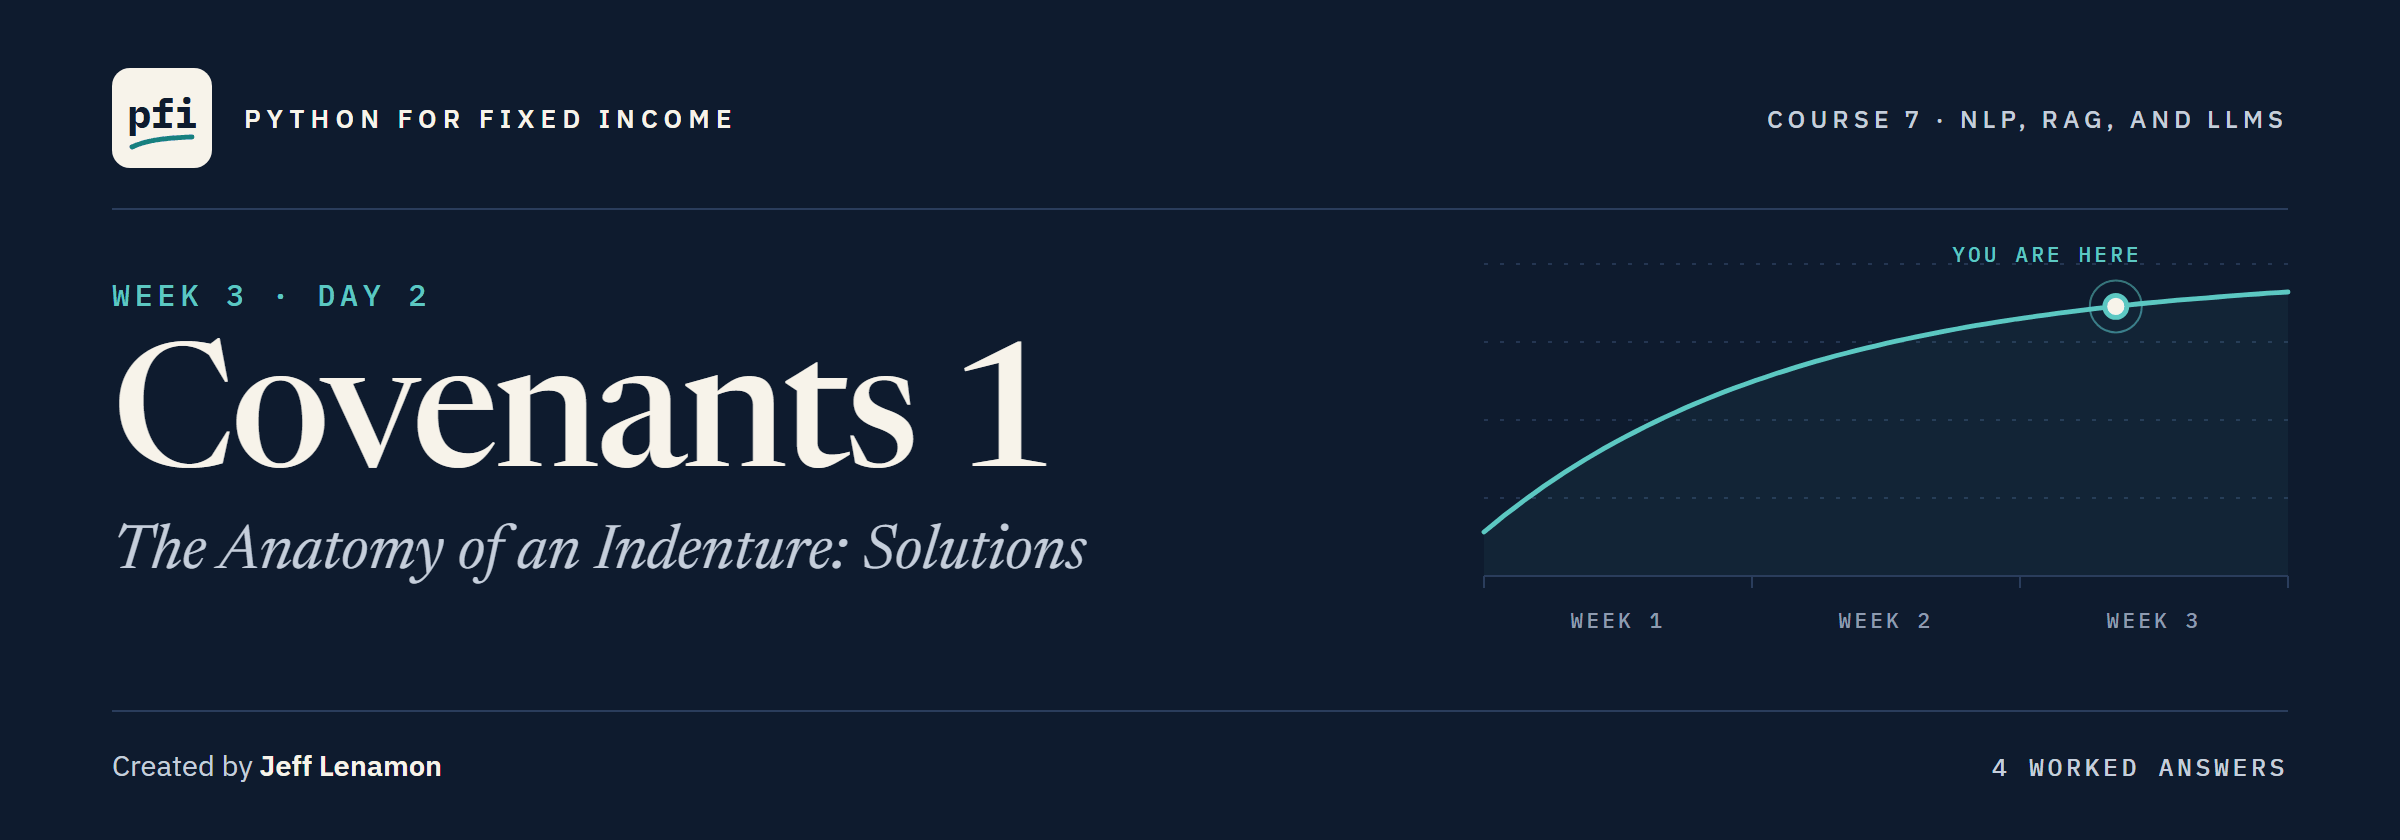

# Covenants 1: The Anatomy of an Indenture: Solutions

Week 3, Day 2. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day2/12_covenants_1_the_anatomy_of_an_indenture_solutions.ipynb)

# Problem Statement

## Business Context

A credit desk records the covenant terms of the notes it follows: how much more debt the issuer may take on and under which test, what it may pay out, what it may pledge, and what holders get on a change of control.
Today it takes one public indenture apart and sends five covenants to a model, one request each.
A value is kept only if code finds its number inside its quote, inside the section the quote cites.
Every response was sent by the course on 2026-10-08 and saved, and the notebook replays it.
A value is "the extracted value": what the document says, never a view of the notes or the issuer.
Nothing is fitted, so nothing is split; every prompt was written on this indenture only.

## Objectives

Name an indenture's parties, articles and covenant sections.
Build the dictionary of defined terms, and list the ones a covenant uses.
Read a covenant's amounts, percentages and ratio test with regular expressions before any model sees it.
Write a schema with pydantic, and validate a response against it.
Send an extraction request that asks for JSON, and read `finish_reason` before parsing.
Check every extracted number against its quote and its section.
Change a prompt one sentence at a time and measure each change.
Put several covenants in one checked table and trace every rejection.

## Data Dictionary

`course7_indentures/boyd_2021.txt`: Day 1's indenture, whole.

`course7_llm_responses/day12/<key>.json`: one saved response a file, with Day 11's fields (`request`, `content`, `model`, `provider`, `usage`, `finish_reason`, `recorded`).

Made in this notebook:

1. `definitions`: each defined term of Section 1.01 and the text of its definition
2. `Quote`, `RatioTest`, `Basket`, `Covenant`: the schema's four classes and their fields
3. the checked table, one row per extracted number: `covenant`, `field`, `value`, `unit`, `section`, `section_exists`, `quote_found`, `number_found`, `passed`

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text, fingerprints, and the one kind of text a field may hold
import hashlib
import json
import re
import sys
import unicodedata
from typing import Literal

# data, charts and the dropdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# the client for a language model, Course 3's reader of a .env file, and the schema library
import openai
from dotenv import dotenv_values
from pydantic import BaseModel

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## Reading Files That Are Not Tables

Day 1's `data_file`: the repo's path on your machine, a copy downloaded once in Colab.

In [3]:
# the course's text, array, PDF and JSON files: from the repo's data folder, or downloaded once from GitHub in Colab
from urllib.request import urlretrieve


def data_file(name):
    """The path of a course data file on this machine (in Colab, a copy fetched from GitHub the first time)."""
    if not DATA.startswith("https://"):
        return DATA + name
    local = Path(name).name
    if not Path(local).exists():
        urlretrieve(DATA + name, local)
    return local

## Day 1's Text Tools

Day 1 wrote these, and `section_text` is its Exercise 3; they are repeated here as one cell.

In [4]:
# Day 1's look-alike map, normalize_text, the source line, the sections and one section's text
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}
SECTION_PATTERN = r"^(?:Section|SECTION) (?P<number>\d+\.\d+)\.? (?P<title>[A-Z\[][^\n]*?)\.?$"


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


def boyd_source(section=None):
    """Print the source line of the Boyd indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495{where}.")


def find_sections(text):
    """The sections of an indenture, in the order of the text: number as text, title, start and end."""
    found = {}
    for heading in re.finditer(SECTION_PATTERN, text, flags=re.MULTILINE):
        found[heading["number"]] = {"number": heading["number"], "title": heading["title"], "start": heading.start()}
    sections = pd.DataFrame(found.values()).sort_values("start", ignore_index=True)
    sections["end"] = sections["start"].shift(-1, fill_value=len(text))
    return sections


def section_text(text, sections, number):
    """The text of one section of an indenture, from its heading to the next section's heading."""
    row = sections.set_index("number").loc[number]
    return text[row["start"]:row["end"]]

## Day 11's Request Tools

Day 11's key cell word for word, then its request tools as one cell, with `ask` reading `day12`'s saved files.
A live run sends each request again, and its text, so its checks, can come back different.

In [5]:
# the key: the environment, then Colab's Secrets panel, then Course 3's .env file; never printed
key = os.environ.get("OPENROUTER_API_KEY")
if "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = key or userdata.get("OPENROUTER_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None
key = key or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENROUTER_API_KEY")
client = openai.OpenAI(base_url="https://openrouter.ai/api/v1", api_key=key, max_retries=0) if key else None
print(f"OpenRouter key loaded: {client is not None}. Mode: {'live' if client is not None else 'replay'}.")

OpenRouter key loaded: False. Mode: replay.


In [6]:
# Day 11's request tools: the system prompt, the two models, their prices, the request key, ask and the LLM line
SYSTEM_PROMPT = (
    "You extract information from the document text in the user message. Quote the text exactly, character for "
    "character, and give the number of the section each quote comes from. Write every number exactly as the text "
    "writes it. If the text does not answer the question, reply NOT IN TEXT. If the user asks for an opinion, a "
    "grade, a comparison of quality, an ordering of securities or issuers, advice about trading, or a view about "
    "the future, reply exactly: REFUSED: this course asks only what the document says"
)
TEXT_MODEL = "nvidia/nemotron-3-super-120b-a12b:free"
FALLBACK_MODEL = "google/gemini-2.5-flash-lite"
NO_REASONING = {"reasoning": {"enabled": False}}
PRICES = {TEXT_MODEL: ("0", "0"), FALLBACK_MODEL: ("0.0000001", "0.0000004")}


def request_key(request):
    """The SHA-256 fingerprint of a request, as 64 hex characters."""
    text = json.dumps(request, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode("ascii")).hexdigest()


def ask(user_message, model=TEXT_MODEL, extra_body=NO_REASONING, temperature=0.0, seed=SEED, max_tokens=2000,
        response_format=None, provider="openrouter", day="day12"):
    """The response to one request: the course's saved one when no key is loaded, else one sent live."""
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_message}]
    params = {"temperature": temperature, "seed": seed, "max_tokens": max_tokens, "response_format": response_format,
              "extra_body": extra_body}
    request = {"provider": provider, "model": model, "messages": messages, "params": params}
    # the notebook's one client is OpenRouter's, so a request on another route always replays
    if client is None or provider != "openrouter":
        saved = Path(data_file(f"course7_llm_responses/{day}/{request_key(request)}.json"))
        return json.loads(saved.read_text(encoding="utf-8"))
    # response_format is sent only when it is set
    options = {} if response_format is None else {"response_format": response_format}
    sent = client.chat.completions.create(model=model, messages=messages, temperature=temperature, seed=seed,
                                          max_tokens=max_tokens, extra_body=extra_body, **options)
    return {"content": sent.choices[0].message.content, "model": sent.model, "provider": sent.model_dump().get("provider"),
            "usage": sent.usage.model_dump(), "finish_reason": sent.choices[0].finish_reason, "recorded": "live",
            "request": request}


def llm_line(response):
    """Print the model, the temperature and seed, and where the response came from."""
    settings = response["request"]["params"]
    if response["recorded"] == "live":
        where = "live."
    elif client is None:
        where = f"saved response recorded {response['recorded']}; replayed (no key loaded)."
    else:
        where = f"saved response recorded {response['recorded']}; replayed (not the client's route)."
    print(f"Model {response['request']['model']}, temperature {settings['temperature']}, seed {settings['seed']}; {where}")

# Loading the Data

## The Indenture and Who Signs It

In [7]:
# source text: quoted as published
# the indenture through normalize_text, its sections by Day 1's rule, then the paragraph that names the parties
boyd = normalize_text(Path(data_file("course7_indentures/boyd_2021.txt")).read_text(encoding="utf-8"))
sections = find_sections(boyd)
print(len(boyd), "characters |", len(sections), "sections, from", sections["number"].iloc[0], "to", sections["number"].iloc[-1])
print(next(line for line in boyd.split("\n") if line.startswith("INDENTURE, dated")))
boyd_source()

392021 characters | 107 sections, from 1.01 to 12.14
INDENTURE, dated as of June 8, 2021, by and among Boyd Gaming Corporation, a Nevada corporation (including any and all successors thereto, the "Company"), the Guarantors (as defined herein) and Wilmington Trust, National Association, as trustee (the "Trustee").
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


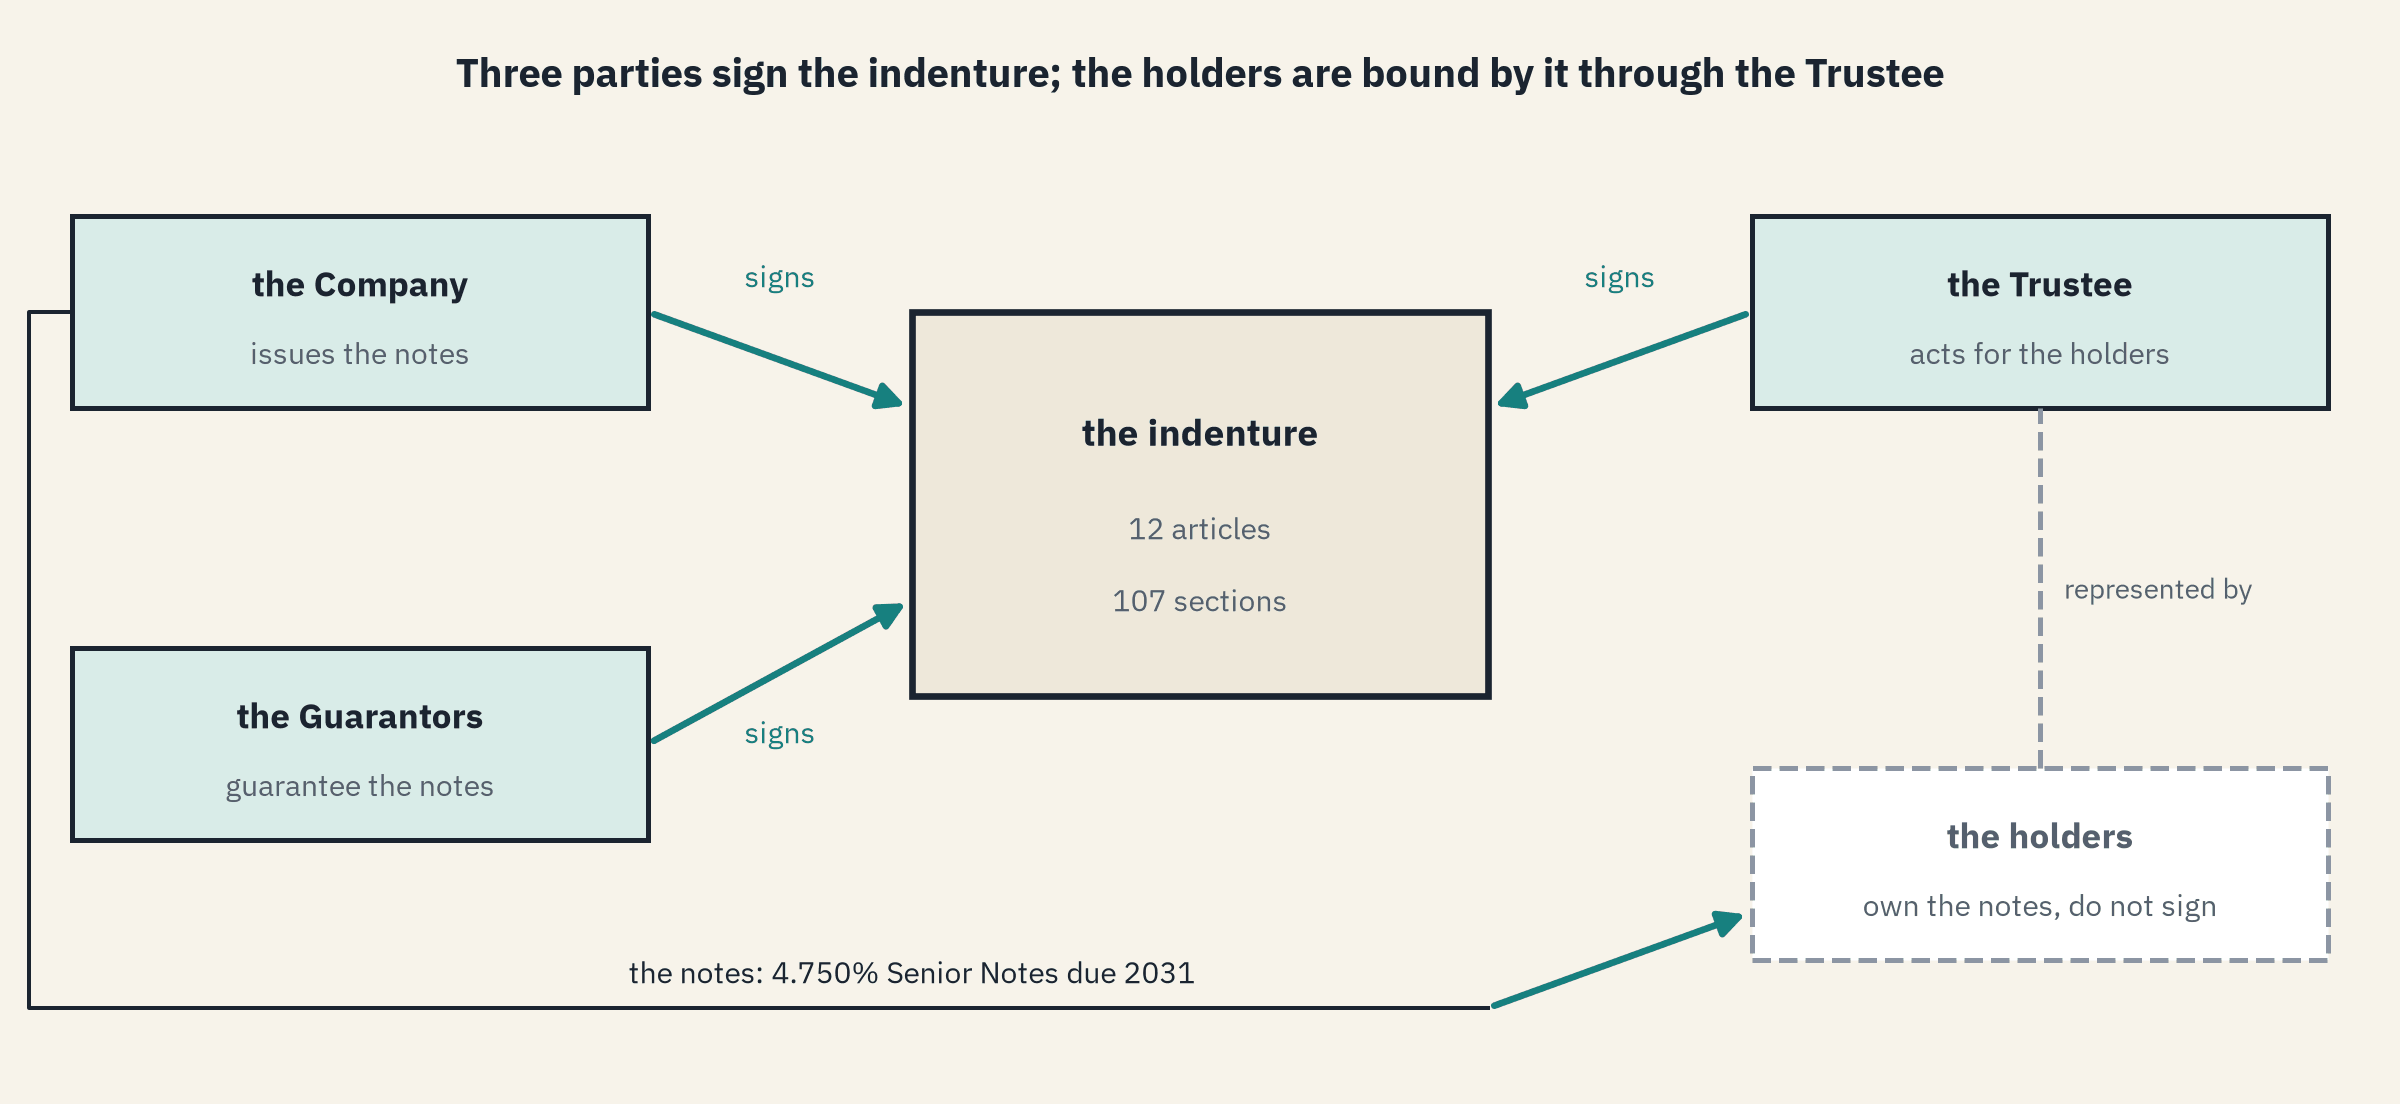

Each signer is a **party**:

* the **Company**, the issuer of the notes;
* the **Guarantors**, subsidiaries that guarantee the notes, named by a definition in Section 1.01;
* the **Trustee**, which acts for the **holders**, who own the notes and do not sign.

**One contract, three signers, 107 numbered sections: every value today cites one of them.**

# The Anatomy of an Indenture

## Twelve Articles

Each article's heading appears twice, in the contents and in the body; as on Day 1, the last one is kept.

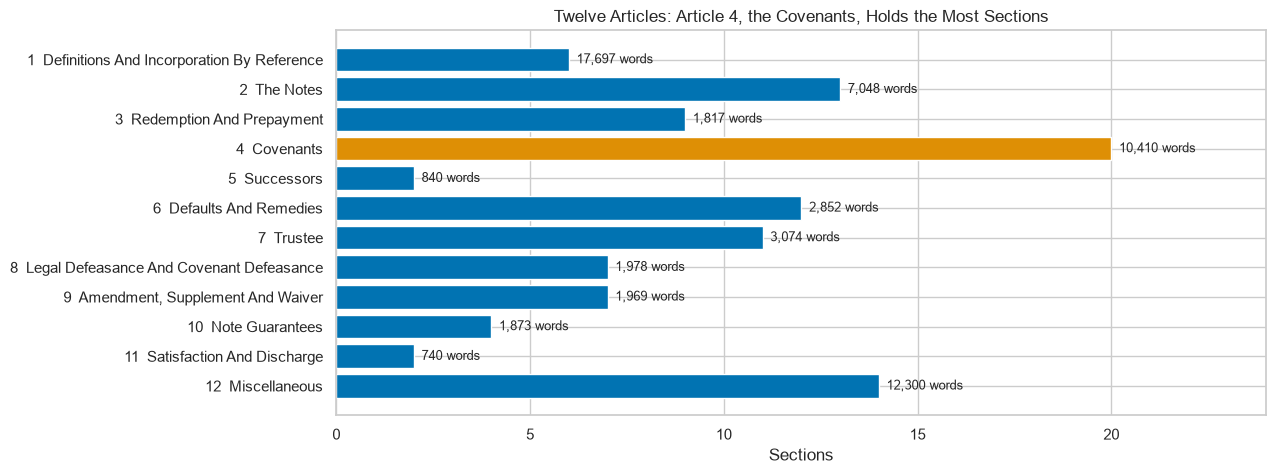

In [8]:
# each article's title, sections and words, drawn as bars of sections with Article 4 in orange
titles = {found[1]: found[2] for found in re.finditer(r"^ARTICLE (\d+)\. (.+)$", boyd, flags=re.MULTILINE)}
sections["article"] = sections["number"].str.split(".").str[0]
sections["words"] = [len(section_text(boyd, sections, number).split()) for number in sections["number"]]
articles = sections.groupby("article", sort=False).agg(sections=("number", "size"), words=("words", "sum"))
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh([f"{article}  {titles[article].title()}" for article in articles.index], articles["sections"],
        color=["C1" if article == "4" else "C0" for article in articles.index])
for y, (count, words) in enumerate(zip(articles["sections"], articles["words"])):
    ax.text(count + 0.2, y, f"{words:,} words", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="Sections", xlim=(0, 24), title="Twelve Articles: Article 4, the Covenants, Holds the Most Sections")
plt.show()

Article 4 holds 20 sections and 10,410 words.

Article 1 holds only 6 sections but 17,697 words: Section 1.01 is the definitions.

Article 12 ends with 12.14, the signature pages and the exhibits.

## Article 4, and Section 12.01

In [9]:
# source text: quoted as published
# the twenty sections of Article 4 by number and title, then the whole of Section 12.01
print(sections.loc[sections["article"] == "4", ["number", "title"]].to_string(index=False))
boyd_source()
print(section_text(boyd, sections, "12.01"))
boyd_source("12.01")

number                                                                                   title
  4.01                                                                        Payment of Notes
  4.02                                                         Maintenance of Office or Agency
  4.03                                                                                 Reports
  4.04                                                                  Compliance Certificate
  4.05                                                                 Stay and Extension Laws
  4.06                                                                     Corporate Existence
  4.07                                           Limitation on Status as an Investment Company
  4.08                                                                              [Reserved]
  4.09                                                              Additional Note Guarantees
  4.10                                            

4.01 to 4.09 are **housekeeping covenants**: pay on time, keep an office, file reports, stay in existence; 4.08 is "[Reserved]".

Today's five: 4.10 Change of Control, 4.11 Asset Sales, 4.12 Limitation on Indebtedness, 4.14 Limitation on Liens and 4.15 Limitation on Restricted Payments.

Section 12.01 says in the indenture's own words that the **Trust Indenture Act** does not apply to it: its terms are the ones it writes.

**The covenants live in Article 4, and their words are defined in Article 1.**

> STORY: A law about trustees.
> Section 77aaa of Title 15 of the United States Code gives the short title "Trust Indenture Act of 1939"; its source credit dates it Aug. 3, 1939.
> Section 77bbb(a) says the interests of investors in publicly offered notes and bonds "are adversely affected", and its paragraph (1) names the first case: "when the obligor fails to provide a trustee to protect and enforce the rights and to represent the interests" of those investors.
> Sources: https://www.law.cornell.edu/uscode/text/15/77aaa and https://www.law.cornell.edu/uscode/text/15/77bbb (read 2026-11-18).

# Defined Terms Are the Dictionary

## `definitions_dict`

Day 1's `defined_terms` found 136 of the 148 quoted-term lines of Section 1.01.
Here every paragraph that starts with a quoted term is a **definition**, whatever words follow, running to the next quoted term; `,?"` drops a comma written inside the closing quote.

In [10]:
# source text: quoted as published
# every paragraph of Section 1.01 that starts with a quoted term: term -> its whole definition
def definitions_dict(text, sections):
    """Every definition in Section 1.01: the quoted term, then its paragraphs up to the next quoted term."""
    part = normalize_text(section_text(text, sections, "1.01"))
    found = list(re.finditer(r'^"(?P<term>[A-Z0-9][^"\n]{0,100}?),?"', part, flags=re.MULTILINE))
    starts = [match.start() for match in found] + [len(part)]
    return {match["term"]: part[start:end].strip() for match, start, end in zip(found, starts[:-1], starts[1:])}


# how many, then two definitions the debt covenant leans on
definitions = definitions_dict(boyd, sections)
print(len(definitions), "definitions |", sum(len(text) for text in definitions.values()), "characters")
for term in ["Consolidated Total Assets", "Consolidated Fixed Charge Coverage Ratio"]:
    print(definitions[term])
boyd_source("1.01")

148 definitions | 107081 characters
"Consolidated Total Assets" of any Person as of any date means the total assets of such Person and its Restricted Subsidiaries as of the most recent fiscal quarter end for which a consolidated balance sheet of such Person and its Restricted Subsidiaries is available, calculated on a consolidated basis in accordance with GAAP and with such pro forma adjustments as are consistent with the definition of "Pro Forma Basis."
"Consolidated Fixed Charge Coverage Ratio" means the ratio of Consolidated EBITDA during the Reference Period to the aggregate amount of Consolidated Fixed Charges during the Reference Period; provided that (other than for purposes of Section 4.12(b)(xiii)) no effect shall be given to (i) any Indebtedness (and associated Consolidated Fixed Charges) Incurred pursuant to Section 4.12(b) on the Calculation Date and (ii) the Discharge of any Indebtedness (and associated Consolidated Fixed Charges) to the extent such Discharge results from 

Consolidated Total Assets: total assets at the latest quarter end, consolidated under GAAP.

The ratio is Consolidated EBITDA over Consolidated Fixed Charges for the Reference Period, each defined in turn; the "6" is the filing's page number.

## `terms_used`

`(?<!\w)` reads "not preceded by" a letter, digit or underscore, and `(?!\w)` "not followed by" one: Day 5's `(?<=...)` was the "preceded by" form.
Together they match a term only as whole words; `re.escape` (Day 9) makes each character match itself.
**Depth 1** is the terms a text uses; **depth 2** adds the terms inside their definitions.

In [11]:
# the defined terms a text uses, case-sensitive and whole, in order of first use (ties by term)
def terms_used(text, definitions, depth=1):
    """The defined terms a text uses, in order of first use; depth=2 adds the terms their definitions use."""
    first = {}
    for term in definitions:
        found = re.search(rf"(?<!\w){re.escape(term)}(?!\w)", text)
        if found:
            first[term] = found.start()
    used = sorted(first, key=lambda term: (first[term], term))
    if depth == 2:
        for term in list(used):
            used += [extra for extra in terms_used(definitions[term], definitions) if extra not in used]
    return used

**Predict 1**

Section 4.12 is 1,819 words long (Day 1).

Q. How many of the 148 defined terms does it use directly, at depth 1? Write down a number.

## The Terms Section 4.12 Uses

In [12]:
# Section 4.12's terms at depth 1 and 2, the first twelve, and the characters of their definitions
body_412 = section_text(boyd, sections, "4.12")
depth1 = terms_used(body_412, definitions)
depth2 = terms_used(body_412, definitions, depth=2)
print(len(depth1), "terms at depth 1 |", len(depth2), "terms at depth 2")
print(depth1[:12])
used_1 = sum(len(definitions[term]) for term in depth1)
all_definitions = sum(len(text) for text in definitions.values())
print(len(body_412), "characters in 4.12 |", used_1, "of definitions at depth 1,", round(100 * used_1 / all_definitions, 1),
      "percent of all |", sum(len(definitions[term]) for term in depth2), "at depth 2")

# for each depth-2 term, the depth-1 term whose definition first uses it
extra = depth2[len(depth1):]
parent = {}
for term in depth1:
    for found in terms_used(definitions[term], definitions):
        if found in extra and found not in parent:
            parent[found] = term
print(len(parent), "depth-2 terms |", sum(term == "Indebtedness" for term in parent.values()), "of them through Indebtedness")

36 terms at depth 1 | 65 terms at depth 2
['Indebtedness', 'Company', 'Restricted Subsidiary', 'Subsidiary', 'Incur', 'Consolidated Fixed Charge Coverage Ratio', 'Reference Period', 'Property', 'Master Lease', 'Additional Lease', 'Project', 'Project Opening']
11869 characters in 4.12 | 26792 of definitions at depth 1, 25.0 percent of all | 51374 at depth 2
29 depth-2 terms | 6 of them through Indebtedness


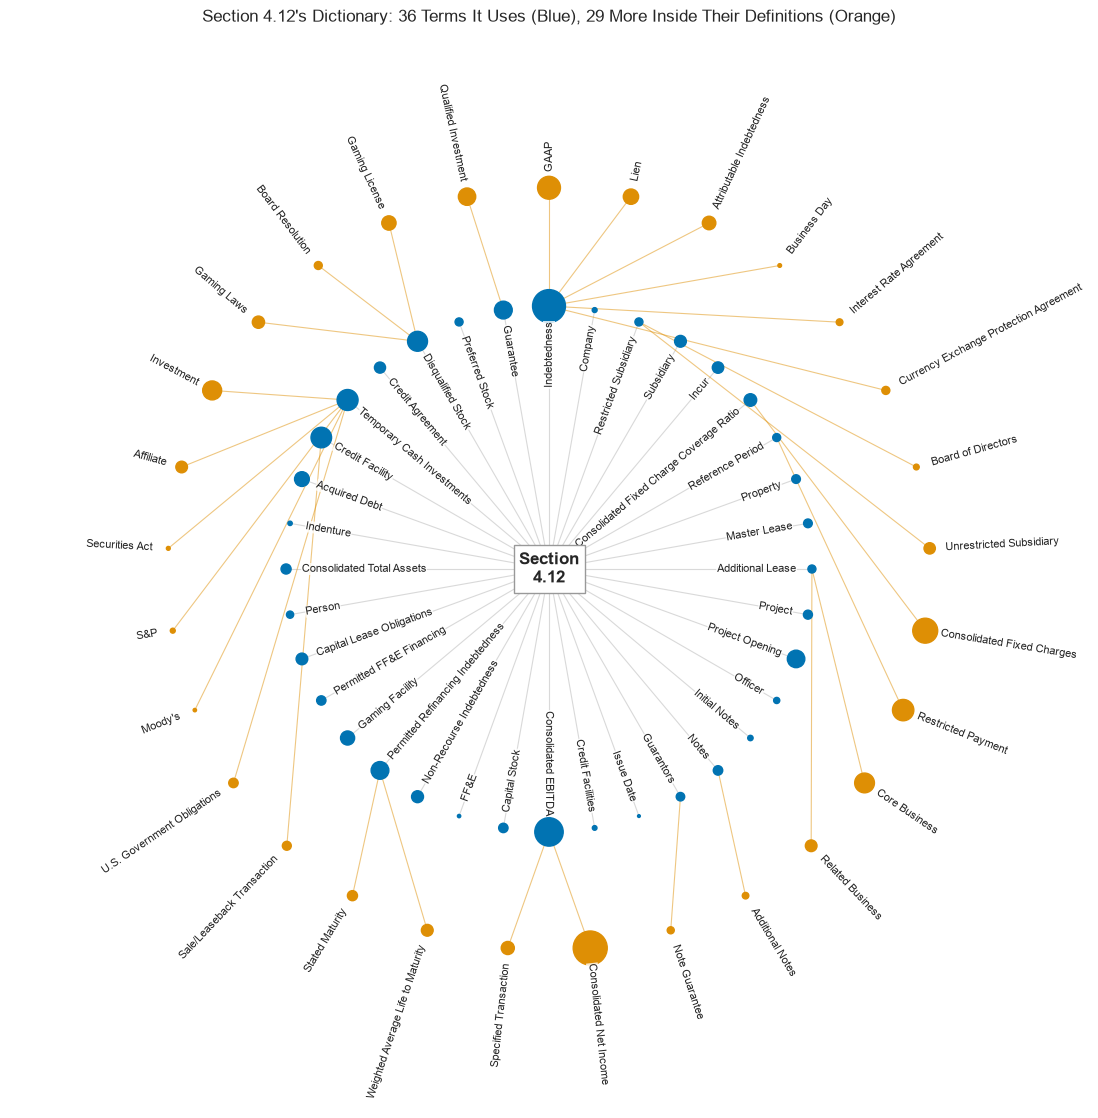

In [13]:
# Section 4.12 at the centre, depth 1 on the inner ring, depth 2 outside, each joined to the term that brought it
inner = {term: np.pi / 2 - 2 * np.pi * i / len(depth1) for i, term in enumerate(depth1)}
outer = {term: np.pi / 2 - 2 * np.pi * i / len(extra) for i, term in enumerate(extra)}
fig, ax = plt.subplots(figsize=(14, 14))
for term, angle in inner.items():
    ax.plot([0, 2.0 * np.cos(angle)], [0, 2.0 * np.sin(angle)], color="0.85", lw=0.8, zorder=0)
for term, angle in outer.items():
    start = inner[parent[term]]
    ax.plot([2.0 * np.cos(start), 2.9 * np.cos(angle)], [2.0 * np.sin(start), 2.9 * np.sin(angle)],
            color="C1", lw=0.8, alpha=0.5)
# the inner ring's names point to the centre, the outer ring's away from it
for radius, spots, colour, step in [(2.0, inner, "C0", -0.12), (2.9, outer, "C1", 0.12)]:
    angles = np.array(list(spots.values()))
    ax.scatter(radius * np.cos(angles), radius * np.sin(angles), s=[len(definitions[t]) / 8 for t in spots],
               color=colour, zorder=3)
    for term, angle in spots.items():
        left_side = np.cos(angle) < 0
        ax.text((radius + step) * np.cos(angle), (radius + step) * np.sin(angle), term,
                rotation=np.degrees(angle) - 180 * left_side, rotation_mode="anchor",
                ha="right" if (step < 0) != left_side else "left", va="center", fontsize=8,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5, "alpha": 0.8})
ax.text(0, 0, "Section\n4.12", ha="center", va="center", fontsize=12, weight="bold",
        bbox={"facecolor": "white", "edgecolor": "0.6"})
ax.set(xlim=(-4.1, 4.1), ylim=(-4.1, 4.1), aspect="equal",
       title="Section 4.12's Dictionary: 36 Terms It Uses (Blue), 29 More Inside Their Definitions (Orange)")
ax.set_axis_off()
plt.show()

### Interpretation of the Rings

A dot's area is its definition's length: Indebtedness and Consolidated EBITDA are the largest inner dots.

Indebtedness and Temporary Cash Investments each bring 6 outer terms.

The 36 definitions hold 26,792 characters, more than twice the section's 11,869.

**A covenant sent without its definitions is sent without most of its meaning, so every request carries the depth-1 definitions.**

# The Covenants, Read by Code

## Every Amount, the Ratio Test and the Growers

A **ratio test** lets the issuer take on new debt, **ratio debt**, while a ratio stays past a level.
A **basket** permits debt, payments or liens up to an amount outside that test; a **grower basket** is the greater of a dollar amount and a share of a defined term.
`.groupdict()` returns a match's named groups as a dictionary.

In [14]:
# source text: quoted as published
# every dollar amount and percentage in today's five sections
AMOUNT = r"\$\d{1,3}(?:,\d{3})*(?:\.\d+)?(?: (?:million|billion))?"
PERCENT = r"\d+(?:\.\d+)?%"
for number in ["4.12", "4.15", "4.14", "4.10", "4.11"]:
    print(number, re.findall(AMOUNT, section_text(boyd, sections, number)), re.findall(PERCENT, section_text(boyd, sections, number)))

# 4.12's ratio test and 4.10's repurchase price with named groups (Day 1), then every "the greater of"
RATIO = r"(?P<name>Consolidated Fixed Charge Coverage Ratio) would have been (?P<direction>at least) (?P<level>\d+\.\d+ to \d+\.\d+)"
print(re.search(RATIO, body_412).groupdict())
OFFER = r"in cash equal to (?P<price>\d+%) of the aggregate principal amount of Notes repurchased"
print("4.10 repurchase price:", re.search(OFFER, section_text(boyd, sections, "4.10"))["price"])
GREATER = r"the greater of (\$[\d,]+) and (\d+\.\d+%) of (?:the Company's )?Consolidated Total Assets"
for term in ["Permitted Liens", "Permitted Investment"]:
    print(term, re.findall(GREATER, definitions[term]))
print("4.12", re.findall(r"greater of \(A\) (\$[\d,.]+(?: billion)?),? and \(B\) ([\d.]+%|[\d.]+ times)", body_412))
print(next(line for line in body_412.split("\n") if "Credit Facilities in an aggregate" in line))
boyd_source()

4.12 ['$3.5 billion', '$50,000,000', '$285,000,000', '$1.00', '$430,000,000'] ['5.0%', '7.5%']
4.15 ['$1.00', '$100,000,000', '$50,000,000', '$500,000,000', '$10,000,000', '$400,000,000'] ['50%', '100%']
4.14 [] []
4.10 ['$2,000', '$1,000', '$2,000', '$2,000', '$1,000', '$2,000'] ['101%', '90%', '101%']
4.11 ['$285,000,000', '$125,000,000', '$125,000,000'] ['75%', '5.0%', '100%', '100%']
{'name': 'Consolidated Fixed Charge Coverage Ratio', 'direction': 'at least', 'level': '2.0 to 1.0'}
4.10 repurchase price: 101%
Permitted Liens [('$430,000,000', '7.5%')]
Permitted Investment [('$855,000,000', '15.0%'), ('$570,000,000', '10.0%')]
4.12 [('$3.5 billion', '4.5 times'), ('$285,000,000', '5.0%'), ('$430,000,000', '7.5%')]
(iii) Indebtedness of the Company or any Restricted Subsidiary under Credit Facilities in an aggregate amount outstanding at any time not to exceed the greater of (A) $3.5 billion, and (B) 4.5 times Consolidated EBITDA during the Reference Period, calculated on a Pro Form

4.14 states no amount: its permissions sit in the definition of "Permitted Liens" in Section 1.01.

On a change of control the Company must offer to buy the notes back, a **repurchase offer**, at 101% of principal; 4.10's dollar amounts are note denominations.

Clause (iii), the credit facility basket, is the greater of a dollar amount and a multiple of Consolidated EBITDA, not a percentage.

Some baskets live in Section 1.01, so a quote may rightly cite "1.01".

**Code already finds every number; the model is asked which basket each belongs to, with a quote code can check.**

# A Schema

## Four Small Classes

A **schema** names each **field** a response must hold and its type, and **validation** tests a response against it.
A class that inherits from pydantic's `BaseModel` (Course 1's `class`) gets that test: each field is one line, `name: type`.
`int | None` is a whole number or nothing (Course 3's `str | None`), and `Literal[...]` allows only the texts listed.

In [15]:
# a quotation and the section it comes from; a ratio test with its quote
class Quote(BaseModel):
    """A quotation from the document and the number of the section it comes from."""
    section: str
    text: str


class RatioTest(BaseModel):
    """A ratio test as the document states it: its name, its level, its unit ("x"), and its direction."""
    name: str
    threshold: float
    unit: str
    direction: str
    quote: Quote


# a basket with its amount and percentage; one covenant holding its ratio test and a list of baskets
class Basket(BaseModel):
    """A permission to incur, pay, or grant up to an amount: fixed, a percentage of a defined term, or the greater
    of the two."""
    name: str
    fixed_amount_usd: int | None
    percent: float | None
    percent_of: str | None
    greater_of: bool
    quote: Quote


class Covenant(BaseModel):
    """One covenant: its kind, its section, its title, its ratio test if it has one, and its baskets."""
    kind: Literal["indebtedness", "restricted_payments", "liens", "asset_sales", "change_of_control",
                  "affiliate_transactions", "covenant_suspension"]
    section: str
    title: str
    ratio_test: RatioTest | None
    baskets: list[Basket]
    quote: Quote

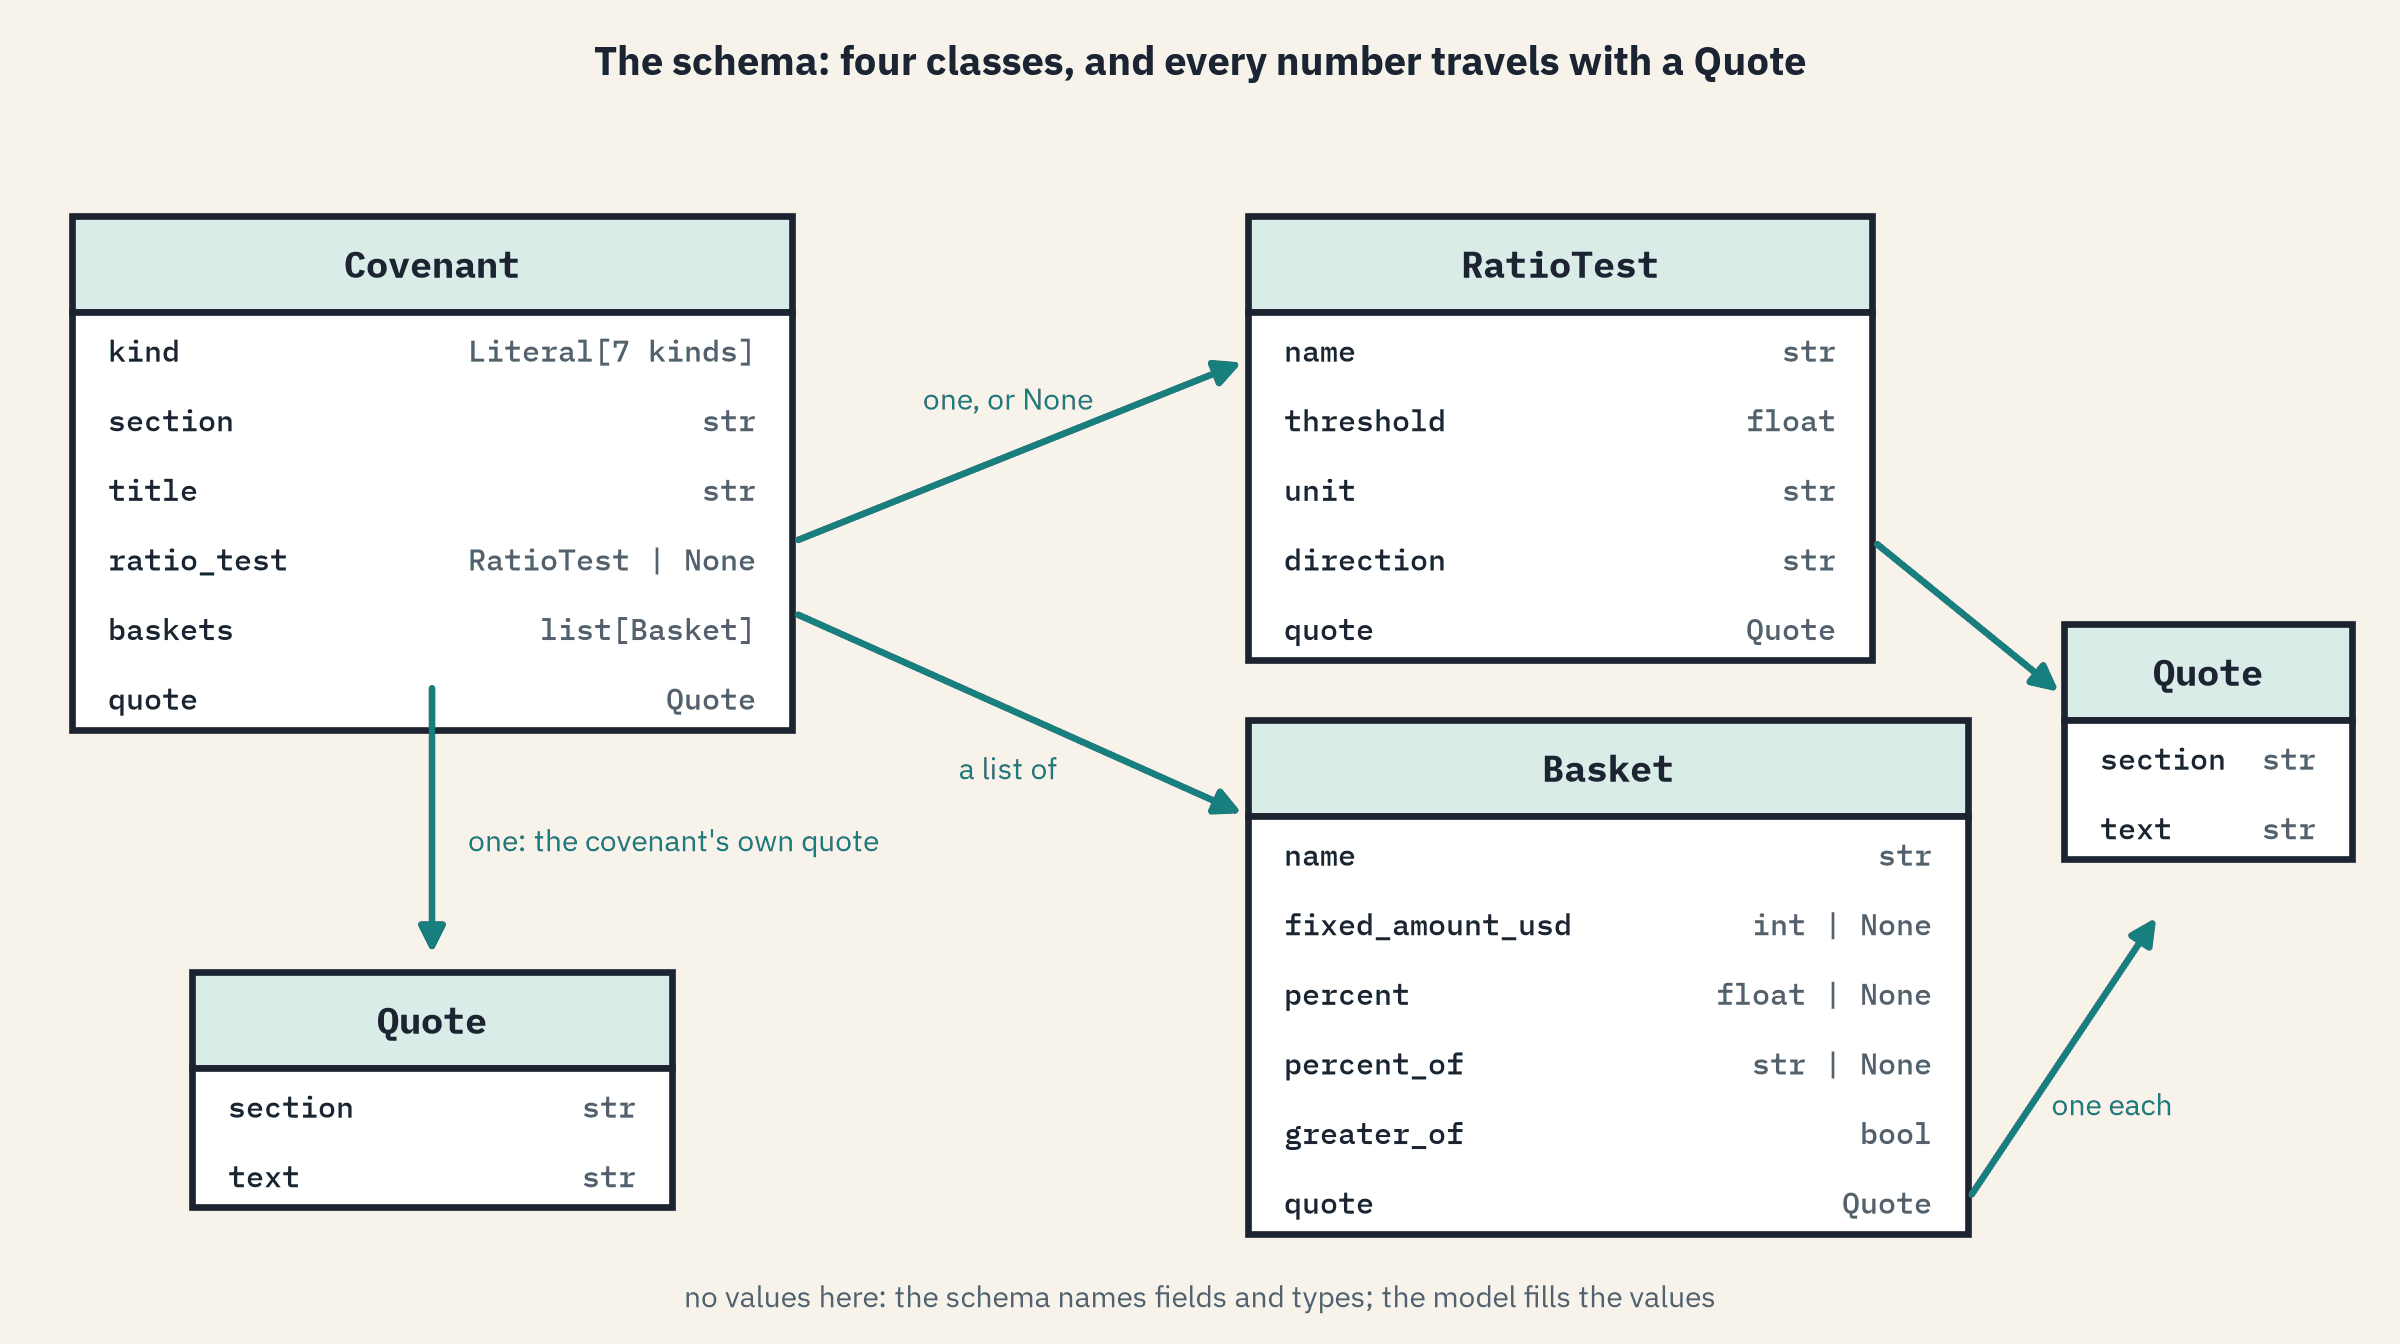

The docstrings and the field order are part of the schema text the model is sent, so they stay word for word as recorded.

## Validating a Dictionary

`.model_validate()` turns a dictionary into a `Quote`, or stops with a `ValidationError` that names the field.

In [16]:
# a dictionary with both fields becomes a Quote; one without text fails validation
quote = Quote.model_validate({"section": "4.12", "text": "the greater of (A) $3.5 billion"})
print(quote)
Quote.model_validate({"section": "4.12"})

section='4.12' text='the greater of (A) $3.5 billion'


ValidationError: 1 validation error for Quote
text
  Field required [type=missing, input_value={'section': '4.12'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.13/v/missing

The last lines name the class, `Quote`, the missing field, `text`, and "Field required".

The link's version number follows the pydantic you have installed, so Colab shows another.

## The Schema as JSON

In [17]:
# the schema as one line of JSON text, the way the model will be sent it
SCHEMA = json.dumps(Covenant.model_json_schema())
print(len(SCHEMA), "characters")
print(SCHEMA[:300])

2217 characters
{"$defs": {"Basket": {"description": "A permission to incur, pay, or grant up to an amount: fixed, a percentage of a defined term, or the greater\nof the two.", "properties": {"name": {"title": "Name", "type": "string"}, "fixed_amount_usd": {"anyOf": [{"type": "integer"}, {"type": "null"}], "title":


**Every number carries a quote and every quote a section: that is what makes a response checkable.**

# The First Extraction

## The Request

**Extraction** asks a model to copy what a document states into fields.
The user message is the instruction with the schema, the definitions the section uses, and the section's exact text, joined by blank lines.
`response_format` set to `JSON_OBJECT` asks for one JSON object; the field names come from the schema in the message.

In [18]:
# the instruction, the user message, and one covenant through ask with the course's extraction settings
def instruction(number, kind, changes=()):
    """What to extract and the schema, then each added sentence on its own line."""
    text = (f'Extract the covenant of Section {number} of the indenture below, of kind "{kind}", as one JSON object '
            f"that fits this JSON schema:\n{SCHEMA}")
    return text + "".join("\n" + sentence for sentence in changes)


def covenant_message(number, kind, changes=(), with_definitions=True):
    """The user message: the instruction, the definitions the section uses, then the section's exact text."""
    body = section_text(boyd, sections, number)
    parts = [instruction(number, kind, changes)]
    if with_definitions:
        used = terms_used(body, definitions)
        parts.append(f"The definitions of Section 1.01 that Section {number} uses ({len(used)} terms):\n"
                     + "\n".join(definitions[term] for term in used))
    parts.append(f"Section {number} of the indenture:\n{body}")
    return "\n\n".join(parts)


JSON_OBJECT = {"type": "json_object"}


def extract(number, kind, changes=(), model=TEXT_MODEL, with_definitions=True):
    """The response to one extraction request; the fallback is sent without NO_REASONING, as recorded."""
    extra_body = NO_REASONING if model == TEXT_MODEL else None
    return ask(covenant_message(number, kind, changes, with_definitions), model=model, extra_body=extra_body,
               max_tokens=4000, response_format=JSON_OBJECT)

41147 characters | [2349, 26894, 11900] | the schema: 2217


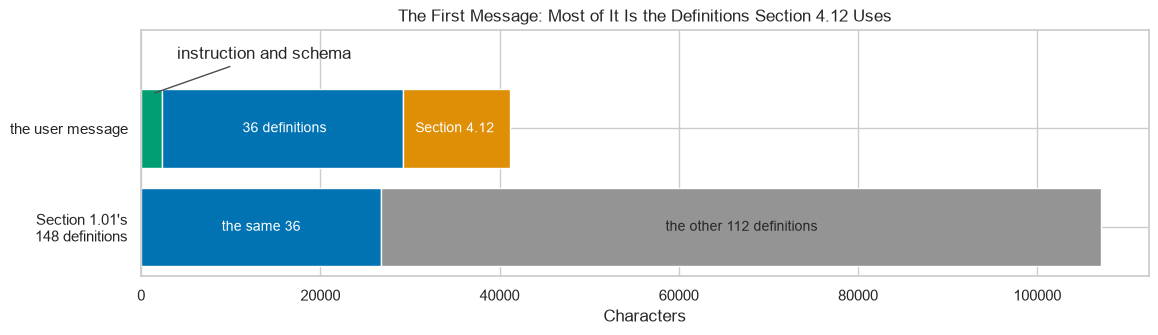

In [19]:
# the first message for Section 4.12 in its three parts, drawn to scale above all 148 definitions
pieces = covenant_message("4.12", "indebtedness").split("\n\n")
print(sum(len(piece) for piece in pieces) + 4, "characters |", [len(piece) for piece in pieces], "| the schema:", len(SCHEMA))
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.barh(1, [len(piece) for piece in pieces], left=np.cumsum([0] + [len(piece) for piece in pieces[:-1]]), color=["C2", "C0", "C1"], edgecolor="white")
ax.barh(0, [used_1, all_definitions - used_1], left=[0, used_1], color=["C0", "C7"], edgecolor="white")
ax.annotate("instruction and schema", xy=(1200, 1.35), xytext=(4000, 1.75), va="center",
            arrowprops={"arrowstyle": "-", "color": "0.3"})
for x, y, words in [(16000, 1, f"{len(depth1)} definitions"), (35000, 1, "Section 4.12"), (13400, 0, f"the same {len(depth1)}")]:
    ax.text(x, y, words, ha="center", va="center", fontsize=10, color="white")
ax.text(67000, 0, f"the other {len(definitions) - len(depth1)} definitions", ha="center", va="center", fontsize=10)
ax.set(yticks=[0, 1], yticklabels=["Section 1.01's\n148 definitions", "the user message"], ylim=(-0.5, 2), xlabel="Characters")
ax.set_title("The First Message: Most of It Is the Definitions Section 4.12 Uses")
plt.show()

The definitions part is 26,894 of the 41,147 characters.

**Predict 2**

The schema has a field for whole dollars and a field for a percentage, and none for a multiple.

Q. Clause (iii) says "the greater of (A) $3.5 billion, and (B) 4.5 times Consolidated EBITDA". What will the response put in `fixed_amount_usd` and in `percent` for that basket? Sketch it in words.

## What Came Back

`finish_reason` is read first: "stop" means the answer is whole, and only a whole answer is parsed.

In [20]:
# LLM response
# the first extraction: why it stopped and its tokens, then the text as JSON (Course 3) and as a Covenant
first = extract("4.12", "indebtedness")
print(first["finish_reason"], "|", first["usage"]["completion_tokens"], "of 4000 completion tokens |", first["usage"]["prompt_tokens"], "prompt tokens")
covenant = Covenant.model_validate(json.loads(first["content"]))
print(covenant.kind, covenant.section, "| ratio test:", covenant.ratio_test.threshold, covenant.ratio_test.unit, covenant.ratio_test.direction)
for basket in covenant.baskets:
    print(basket.name, "|", basket.fixed_amount_usd, "|", basket.percent, "|", basket.percent_of)
llm_line(first)

stop | 3441 of 4000 completion tokens | 9308 prompt tokens
indebtedness 4.12 | ratio test: 2.0 x at least
Credit Facilities | 3500000000 | 4.5 | Consolidated EBITDA
Capital expenditures | 285000000 | 5.0 | Consolidated Total Assets
Other Indebtedness | 430000000 | 7.5 | Consolidated Total Assets
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The response fits the schema: a ratio test of 2.0 x and three baskets, each with its quote.

The credit facility basket holds 3,500,000,000 in `fixed_amount_usd` and 4.5 in `percent`, of Consolidated EBITDA.

**The response fits the schema; fitting says nothing about whether its numbers are the document's.**

# Checking Every Number

Three checks, run by code on every extracted number:

1. the cited section exists;
2. the quote is in that section, both sides through `normalize_text` with white space made single spaces;
3. the number is in the quote.

## The Ways a Number Is Written, Whole

The text writes US$3.5 billion, the response 3500000000: the number check tries each **written form of a number**; `:g` drops trailing zeros.
Day 11's Exercise 3 put `\b` before the number only, which still finds "855" inside "$855,000,000".
`(?<![\d.,])` says not preceded by a digit, full stop or comma; `(?![.,]?\d)` says not followed by a digit, even after one full stop or comma.

In [21]:
# the written forms of a value, and True when one of them stands whole in a quote
def number_forms(value, unit):
    """The ways the text may write a number, with no dollar sign."""
    if unit == "USD":
        forms = [f"{int(value):,}"]
        if value >= 1e6:
            forms.append(f"{value / 1e6:,g} million")
        if value >= 1e9:
            forms.append(f"{value / 1e9:g} billion")
    elif unit == "%":
        forms = [f"{value:g}%", f"{value:.1f}%"]
    else:
        forms = [f"{value:.1f} to 1.0", f"{value:.2f} to 1.00", f"{value:g} to 1"]
    return [form for i, form in enumerate(forms) if form not in forms[:i]]


def number_found(value, unit, quote):
    """True when one written form of the number stands whole in the quote."""
    for form in number_forms(value, unit):
        if re.search(r"(?<![\d.,])" + re.escape(form) + r"(?![.,]?\d)", quote):
            return True
    return False


# three values' forms, then three strings against Day 11's check
for value, unit in [(3_500_000_000, "USD"), (5.0, "%"), (2.0, "x")]:
    print(value, unit, number_forms(value, unit))
for value, unit, text in [(855, "USD", "$855,000,000"), (5.0, "%", "7.5%"), (285_000_000, "USD", "$285,000,000, and")]:
    day11 = any(re.search(r"\b" + re.escape(form), text) for form in number_forms(value, unit))
    print(f"{value} in {text!r}: Day 11's check {day11} | number_found {number_found(value, unit, text)}")

3500000000 USD ['3,500,000,000', '3,500 million', '3.5 billion']
5.0 % ['5%', '5.0%']
2.0 x ['2.0 to 1.0', '2.00 to 1.00', '2 to 1']
855 in '$855,000,000': Day 11's check True | number_found False
5.0 in '7.5%': Day 11's check True | number_found False
285000000 in '$285,000,000, and': Day 11's check True | number_found True


![The number check on three strings, character by character: 855 is refused inside 855,000,000 because a comma and digits follow it, 5 percent is refused inside 7.5 percent because a full stop comes before it, and 285,000,000 is found because a comma and a space follow it](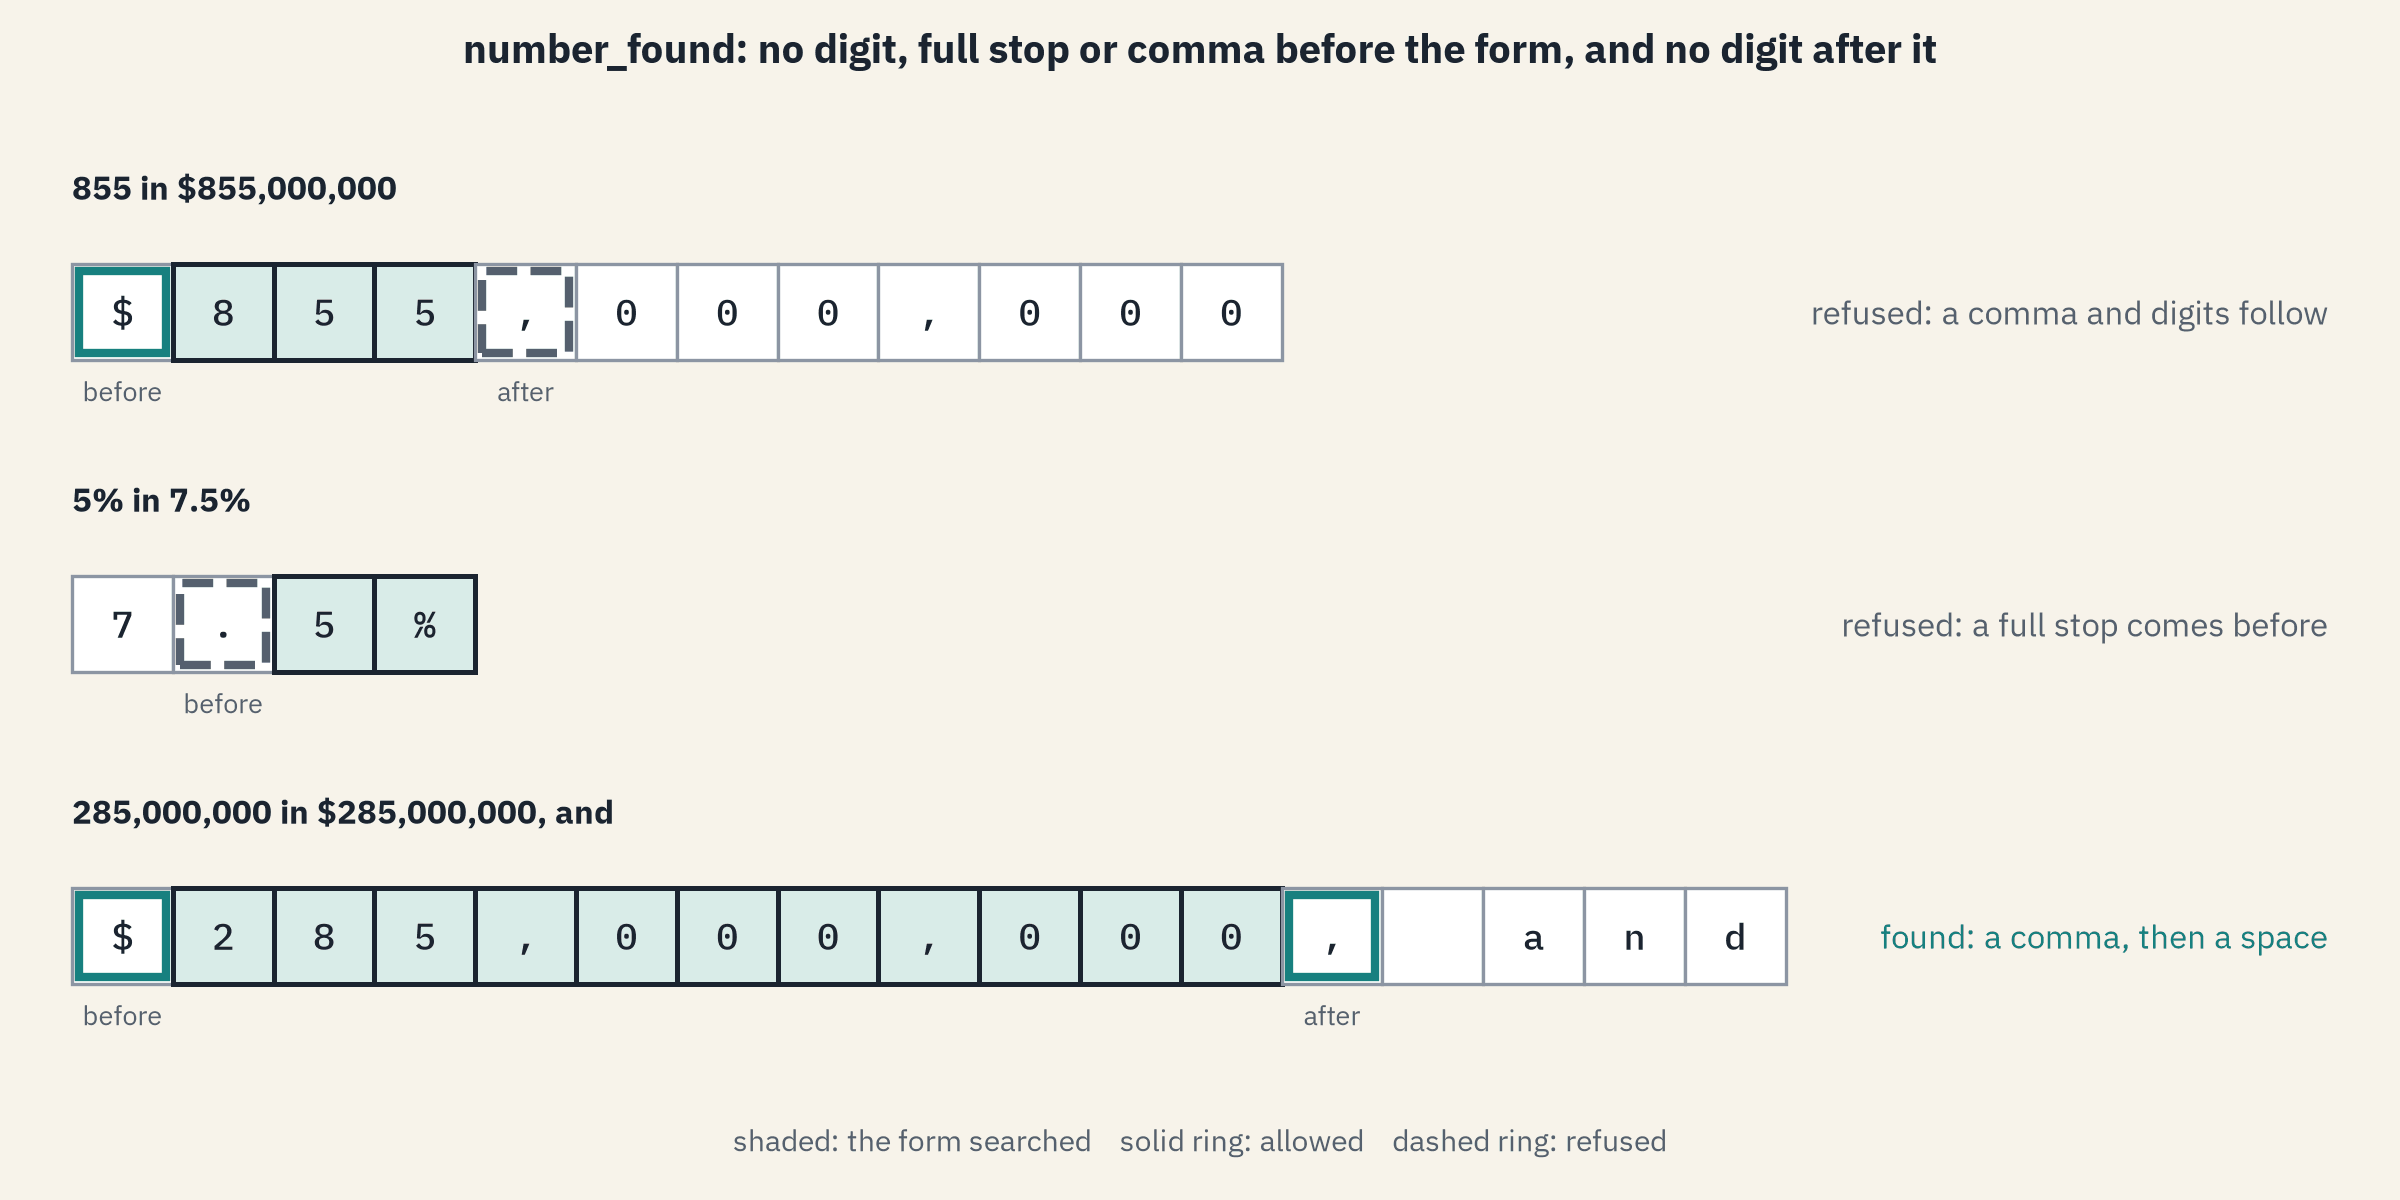)

The first two are false matches for Day 11's check; `number_found` refuses both and still finds the third.

## `check_extraction`

`plain` makes both sides of the quote check alike; `covenant_values` lists every number a covenant holds.

In [22]:
# both sides alike; every number of a covenant; then one row per number with the three checks
def plain(text):
    """Text through normalize_text, every run of white space one space."""
    return re.sub(r"\s+", " ", normalize_text(text))


def covenant_values(covenant):
    """(field, value, unit, quote) for the ratio test and every basket amount and percentage."""
    values = []
    if covenant.ratio_test is not None:
        values.append(("ratio_test", covenant.ratio_test.threshold, "x", covenant.ratio_test.quote))
    for basket in covenant.baskets:
        if basket.fixed_amount_usd is not None:
            values.append((basket.name + ": fixed_amount_usd", basket.fixed_amount_usd, "USD", basket.quote))
        if basket.percent is not None:
            values.append((basket.name + ": percent", basket.percent, "%", basket.quote))
    return values


def check_extraction(covenant):
    """The checked table of one covenant: one row per number, its section, and the three checks."""
    rows = []
    for field, value, unit, quote in covenant_values(covenant):
        exists = quote.section in set(sections["number"])
        quote_found = exists and plain(quote.text) in plain(section_text(boyd, sections, quote.section))
        number = number_found(value, unit, plain(quote.text))
        rows.append([covenant.kind, field, value, unit, quote.section, exists, quote_found, number, exists and quote_found and number])
    return pd.DataFrame(rows, columns=["covenant", "field", "value", "unit", "section", "section_exists", "quote_found", "number_found", "passed"])


# the first response's checked table
first_checks = check_extraction(covenant)
print(first_checks.drop(columns=["covenant", "unit"]).to_string(index=False))
print(int(first_checks["passed"].sum()), "of", len(first_checks), "values pass")

                                 field        value section  section_exists  quote_found  number_found  passed
                            ratio_test          2.0    4.12            True         True          True    True
   Credit Facilities: fixed_amount_usd 3500000000.0    4.12            True         True          True    True
            Credit Facilities: percent          4.5    4.12            True         True         False   False
Capital expenditures: fixed_amount_usd  285000000.0    4.12            True         True          True    True
         Capital expenditures: percent          5.0    4.12            True         True          True    True
  Other Indebtedness: fixed_amount_usd  430000000.0    4.12            True         True          True    True
           Other Indebtedness: percent          7.5    4.12            True         True          True    True
6 of 7 values pass


The **checked table** has one row per **extracted value**; a value that fails a check is a **rejected value**.

The credit facility's 4.5 fails the number check: clause (iii) holds no "4.5%".

## The Quotes in the Section

A match's `.span()` gives its start and its end together.

In [23]:
# the lines of 4.12 the first response quotes; where each quote sits (passed only if all its values pass) and each number
def number_span(value, unit, text):
    """Where a written form of the number, or else the bare number, stands whole in the text."""
    for form in number_forms(value, unit) + [f"{value:g}"]:
        found = re.search(r"(?<![\d.,])" + re.escape(form) + r"(?![.,]?\d)", text)
        if found:
            return found.span()


quotes = [plain(quote.text) for field, value, unit, quote in covenant_values(covenant)]
shown = "\n".join(line for line in body_412.split("\n") if any(line in text or text in line for text in quotes))
quote_spans, number_spans = {}, []
for (field, value, unit, quote), passed in zip(covenant_values(covenant), first_checks["passed"]):
    start = plain(shown).index(plain(quote.text))
    end = start + len(plain(quote.text))
    quote_spans[(start, end)] = quote_spans.get((start, end), True) and passed
    a, b = number_span(value, unit, shown[start:end])
    number_spans.append((start + a, start + b, passed))
print(len(shown), "characters |", len(quote_spans), "quotes |", [shown[a:b] for a, b, passed in number_spans])

1741 characters | 4 quotes | ['2.0 to 1.0', '3.5 billion', '4.5', '285,000,000', '5.0%', '430,000,000', '7.5%']


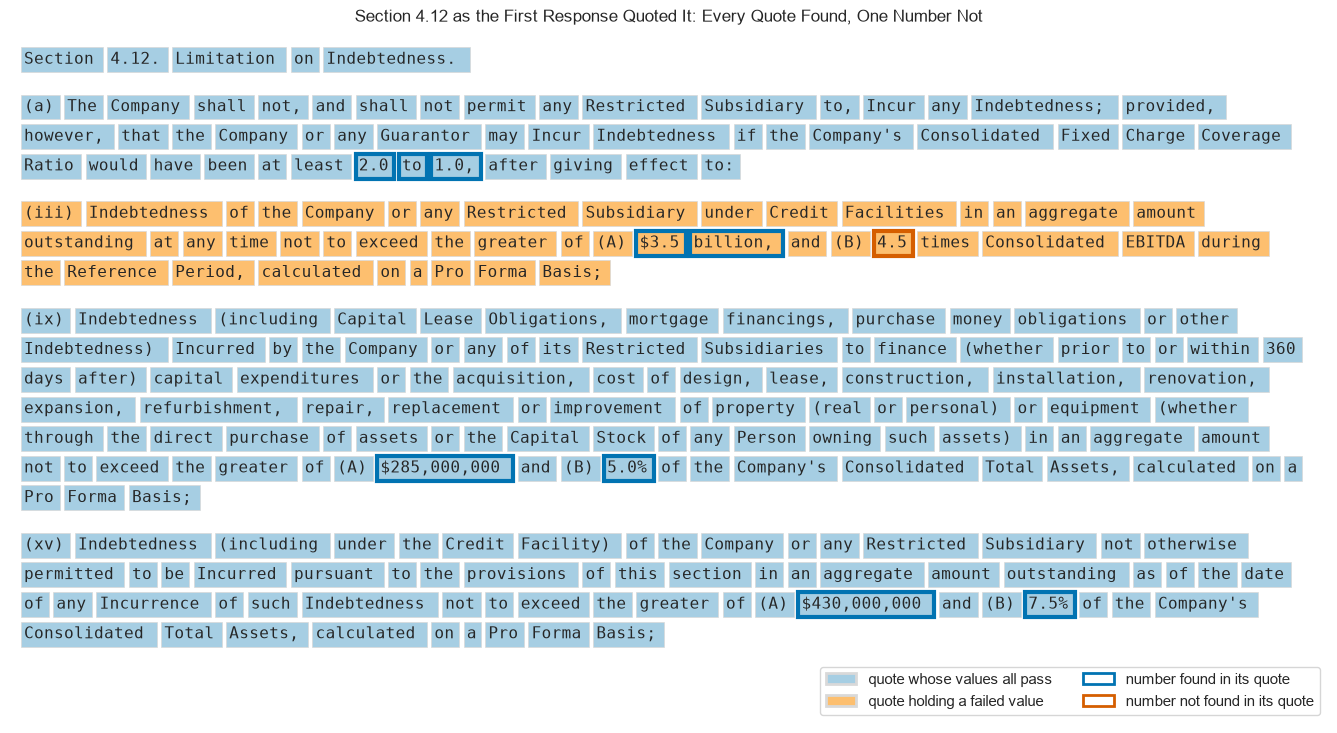

11706 of 11869 characters of Section 4.12 in the covenant's own quote


In [24]:
# the lines as word boxes, one character a unit; a quote shaded by its checks, each number outlined
fig, ax = plt.subplots(figsize=(17, 9))
x, y, last = 0, 0, 0
for word in re.finditer(r"\S+", shown):
    if x and ("\n" in shown[last:word.start()] or x + len(word[0]) > 118):
        x, y = 0, y - (1.6 if "\n" in shown[last:word.start()] else 1)
    fill = next((("#A6CEE3" if ok else "#FDBF6F") for (a, b), ok in quote_spans.items() if a <= word.start() < b), "white")
    edge = next((("#0173B2" if ok else "#D55E00") for a, b, ok in number_spans if a < word.end() and word.start() < b), None)
    ax.add_patch(plt.Rectangle((x, y - 0.42), len(word[0]) + 0.6, 0.84, facecolor=fill, edgecolor=edge or "0.85",
                               lw=3 if edge else 0.5))
    ax.text(x + 0.3, y, word[0], va="center", fontsize=11.5, family="monospace", parse_math=False)
    x, last = x + len(word[0]) + 1, word.end()
# the fill tells a quote's checks, the outline a number's
keys = [plt.Rectangle((0, 0), 1, 1, facecolor=c, edgecolor=e, lw=2)
        for c, e in [("#A6CEE3", "0.85"), ("#FDBF6F", "0.85"), ("white", "#0173B2"), ("white", "#D55E00")]]
ax.legend(handles=keys, labels=["quote whose values all pass", "quote holding a failed value", "number found in its quote",
                                "number not found in its quote"], loc="lower right", ncol=2)
ax.set(xlim=(-1, 121), ylim=(y - 3, 1),
       title="Section 4.12 as the First Response Quoted It: Every Quote Found, One Number Not")
ax.set_axis_off()
plt.show()
print(len(covenant.quote.text), "of", len(body_412), "characters of Section 4.12 in the covenant's own quote")

### Interpretation of the Highlighter

Every quote is in the section, word for word.

The schema has no field for a multiple, so "4.5 times" went into `percent`, and the number check caught it.

The covenant's own quote is nearly the whole section: much of the 3,441 completion tokens is copied text.

**A value enters the table only with a quote that holds it in a section that exists; the checks never say the value belongs to its field.**

# Prompt Changes, One at a Time

## One Sentence per Request

A **prompt change** is one sentence added to the instruction, chosen on this indenture from the response before it.

In [25]:
# LLM response
# change 1: quotes copied exactly, and a section heading's number
QUOTE_SENTENCE = ("Copy every quote exactly as the text writes it, one clause of at most 60 words, and give its section as the "
                  "number of a section heading, such as 4.12 or 1.01, never a clause such as 4.12(b).")
one = extract("4.12", "indebtedness", [QUOTE_SENTENCE])
one_checks = check_extraction(Covenant.model_validate(json.loads(one["content"])))
print(one["finish_reason"], "|", one["usage"]["completion_tokens"], "completion tokens |", len(json.loads(one["content"])["baskets"]), "baskets |",
      int(one_checks["passed"].sum()), "of", len(one_checks), "values pass")
llm_line(one)

stop | 2207 completion tokens | 17 baskets | 6 of 7 values pass
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


In [26]:
# LLM response
# change 2: numbers as the text writes them, in the schema's fields
NUMBER_SENTENCE = ('Write every number as the text writes it: a dollar amount as a whole number of dollars in fixed_amount_usd, '
                   'a percentage in percent, a ratio such as 2.0 to 1.0 as threshold 2.0 with unit "x", and fill every '
                   'amount the quote holds.')
two = extract("4.12", "indebtedness", [QUOTE_SENTENCE, NUMBER_SENTENCE])
two_checks = check_extraction(Covenant.model_validate(json.loads(two["content"])))
print(two["finish_reason"], "|", two["usage"]["completion_tokens"], "completion tokens |", len(json.loads(two["content"])["baskets"]), "baskets |",
      int(two_checks["passed"].sum()), "of", len(two_checks), "values pass")
llm_line(two)

stop | 745 completion tokens | 3 baskets | 6 of 7 values pass
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


In [27]:
# LLM response
# change 3: only baskets with an amount or a percentage, null where the text is silent
BASKET_SENTENCE = ("List only the baskets that state a dollar amount or a percentage, and use null for a field the text does "
                   "not state. If the section holds no covenant of this kind, reply NOT IN TEXT.")
CHANGES = [QUOTE_SENTENCE, NUMBER_SENTENCE, BASKET_SENTENCE]
three = extract("4.12", "indebtedness", CHANGES)
three_checks = check_extraction(Covenant.model_validate(json.loads(three["content"])))
print(three["finish_reason"], "|", three["usage"]["completion_tokens"], "completion tokens |", len(json.loads(three["content"])["baskets"]), "baskets |",
      int(three_checks["passed"].sum()), "of", len(three_checks), "values pass")
print(three_checks.loc[three_checks["field"].str.startswith("Credit"), ["field", "value"]].to_string(index=False))
llm_line(three)

stop | 727 completion tokens | 3 baskets | 6 of 6 values pass
                              field        value
Credit Facilities: fixed_amount_usd 3500000000.0
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


Change 1 trimmed the answer from 3,441 to 2,207 completion tokens and listed 17 baskets, only 3 with a number.

Change 2 brought the baskets back to 3 and the tokens to 745; the 4.5 stayed in `percent`.

Change 3 left the credit facility's `percent` empty, and every value passes.

## Your Turn: Four Prompts

Pick a prompt to see its values by the three checks.

In [28]:
# one response's values by the three checks, yes in blue and no in orange
four = {"first prompt": first, "change 1": one, "change 2": two, "change 3": three}


def draw_checks(prompt="first prompt"):
    table = check_extraction(Covenant.model_validate(json.loads(four[prompt]["content"])))
    grid = table.set_index("field")[["section_exists", "quote_found", "number_found"]].astype(int)
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(grid) + 1.5))
    sns.heatmap(grid, annot=grid.replace({1: "yes", 0: "no"}), fmt="", cmap=["#DE8F05", "#56B4E9"], vmin=0, vmax=1,
                cbar=False, linewidths=1, ax=ax)
    ax.set(ylabel="", title=f"{prompt.title()}: {int(table['passed'].sum())} of {len(table)} Values Pass Every Check")
    plt.show()


interact(draw_checks, prompt=list(four));

interactive(children=(Dropdown(description='prompt', options=('first prompt', 'change 1', 'change 2', 'change …

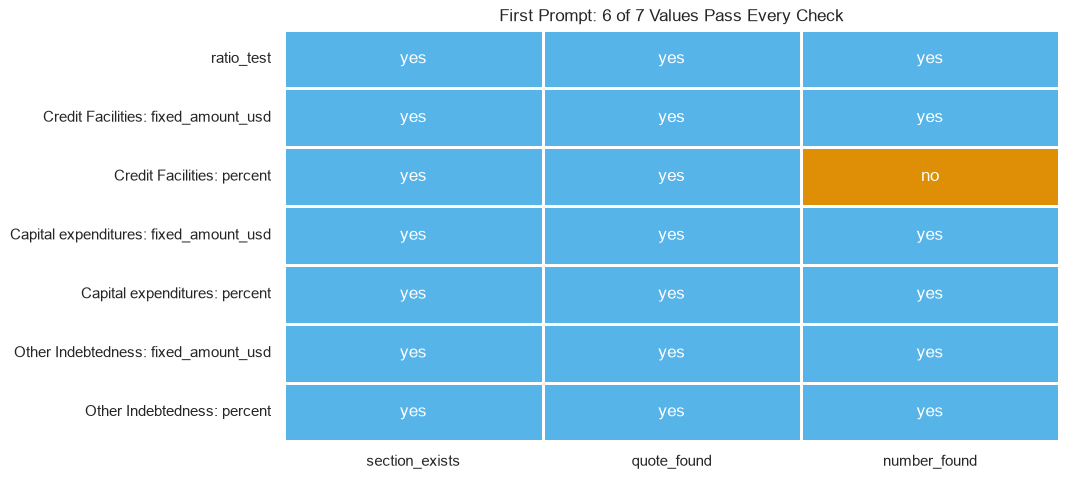

In [29]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_checks(prompt="first prompt")

**Predict 3**

On the same prompt, with all three sentences, the free model returned 6 values and all 6 pass.

Q. How many values does the paid fallback return? Write down a number.

## The Same Prompt on the Paid Fallback

In [30]:
# LLM response
# the change 3 prompt on the fallback: its values, checks and the direction it wrote
fallback = extract("4.12", "indebtedness", CHANGES, model=FALLBACK_MODEL)
fallback_cov = Covenant.model_validate(json.loads(fallback["content"]))
fallback_checks = check_extraction(fallback_cov)
print(len(fallback_checks), "values,", int(fallback_checks["passed"].sum()), "pass |", len(fallback_cov.baskets), "baskets | percent:",
      [basket.percent for basket in fallback_cov.baskets], "| direction:", fallback_cov.ratio_test.direction)
llm_line(fallback)

4 values, 4 pass | 4 baskets | percent: [None, None, None, None] | direction: greater than or equal to
Model google/gemini-2.5-flash-lite, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


In [31]:
# the fallback's cost by hand at Day 11's list prices, against what the response says it was billed
prompt_price, completion_price = PRICES[FALLBACK_MODEL]
by_hand = fallback["usage"]["prompt_tokens"] * float(prompt_price) + fallback["usage"]["completion_tokens"] * float(completion_price)
print(fallback["usage"]["prompt_tokens"], "prompt and", fallback["usage"]["completion_tokens"], f"completion tokens | by hand US${by_hand:.7f} | billed US${fallback['usage']['cost']:.7f}")

9075 prompt and 1524 completion tokens | by hand US$0.0015171 | billed US$0.0015171


In [32]:
# the five 4.12 runs: values passed and not passed, and the completion tokens each used
runs = {"first prompt": first, "change 1": one, "change 2": two, "change 3": three, "change 3, paid fallback": fallback}
verdicts = {name: check_extraction(Covenant.model_validate(json.loads(run["content"])))["passed"] for name, run in runs.items()}
tallies = pd.DataFrame({"passed": [int(v.sum()) for v in verdicts.values()], "not passed": [int((~v).sum()) for v in verdicts.values()]}, index=list(runs))
tallies["completion tokens"] = [run["usage"]["completion_tokens"] for run in runs.values()]
print(tallies.to_string())

                         passed  not passed  completion tokens
first prompt                  6           1               3441
change 1                      6           1               2207
change 2                      6           1                745
change 3                      6           0                727
change 3, paid fallback       4           0               1524


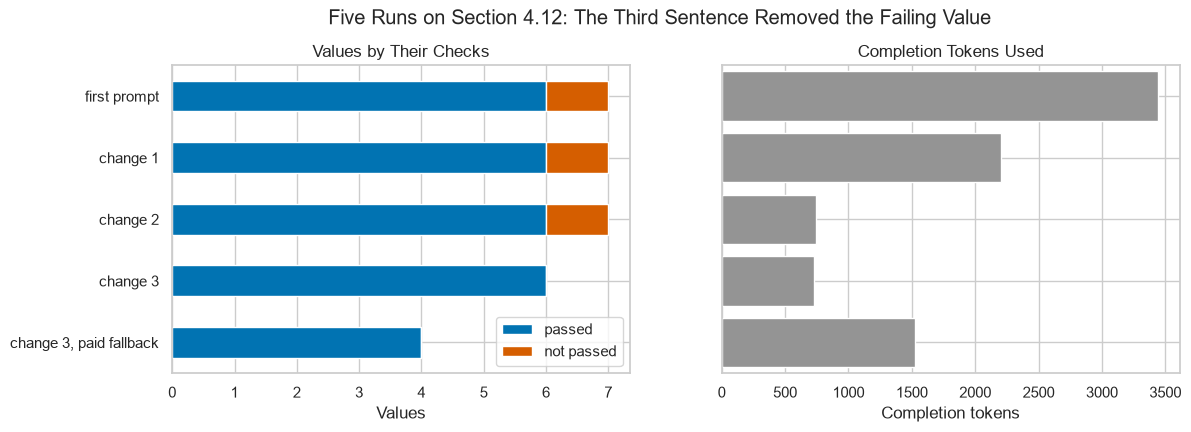

In [33]:
# the five runs as stacked bars of values, beside their completion tokens
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
tallies[["passed", "not passed"]].plot.barh(stacked=True, color=["C0", "C3"], ax=left)
left.set(xlabel="Values", ylabel="", title="Values by Their Checks")
right.barh(tallies.index, tallies["completion tokens"], color="C7")
right.set(xlabel="Completion tokens", title="Completion Tokens Used")
left.invert_yaxis()
fig.suptitle("Five Runs on Section 4.12: The Third Sentence Removed the Failing Value", y=1.02)
plt.show()

### Interpretation of the Fallback

The fallback left `percent` empty in all four baskets and wrote the ratio's direction as "greater than or equal to" where the text says "at least".

Its fourth basket holds no number, so it adds no row: the checks test what comes back, never what is missing, and a text field such as `direction` is not checked at all.

Its cost by hand equals its billed cost.

**One change, one measurement: the sentence that removed the failing value is the third.**

# Five Covenants in One Checked Table

## The Five Requests

In [34]:
# the five covenants in the course's order, each sent with all three sentences (4.12 replays change 3's file)
COVENANTS = [("4.12", "indebtedness"), ("4.15", "restricted_payments"), ("4.14", "liens"), ("4.10", "change_of_control"),
             ("4.11", "asset_sales")]
responses = {number: extract(number, kind, CHANGES) for number, kind in COVENANTS}
covenants = {number: Covenant.model_validate(json.loads(response["content"])) for number, response in responses.items()}
for number, response in responses.items():
    print(number, response["finish_reason"], response["usage"]["completion_tokens"], "completion tokens | baskets:",
          len(covenants[number].baskets))

4.12 stop 727 completion tokens | baskets: 3
4.15 stop 1109 completion tokens | baskets: 6
4.14 stop 977 completion tokens | baskets: 1
4.10 stop 66 completion tokens | baskets: 0
4.11 stop 300 completion tokens | baskets: 1


**Predict 4**

The five covenants hold 12 numbers between them.

Q. How many pass all three checks? Write down a number.

## The Checked Table

In [35]:
# LLM response
# the checked tables of the covenants that returned a value, stacked, then the values and passes by covenant
table = pd.concat([check_extraction(covenants[number]) for number, kind in COVENANTS if covenant_values(covenants[number])],
                  ignore_index=True)
print(len(table), "values |", int(table["passed"].sum()), "pass")
print(table.groupby("covenant", sort=False)["passed"].agg(["size", "sum"]).to_string())
llm_line(responses["4.12"])

12 values | 10 pass
                     size  sum
covenant                      
indebtedness            6    6
restricted_payments     2    2
liens                   2    0
asset_sales             2    2
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


In [36]:
# the 12 values by the three checks, grouped by covenant, with a row for the covenant that returned none
grid = table.set_index(table["covenant"] + " | " + table["field"])[["section_exists", "quote_found", "number_found"]].astype(int)
grid.loc["change_of_control | no value returned"] = -1
grid = grid.loc[sorted(grid.index, key=lambda label: [kind for number, kind in COVENANTS].index(label.split(" | ")[0]))]
print(len(table), "values and one row for change_of_control:", len(grid), "rows")

12 values and one row for change_of_control: 13 rows


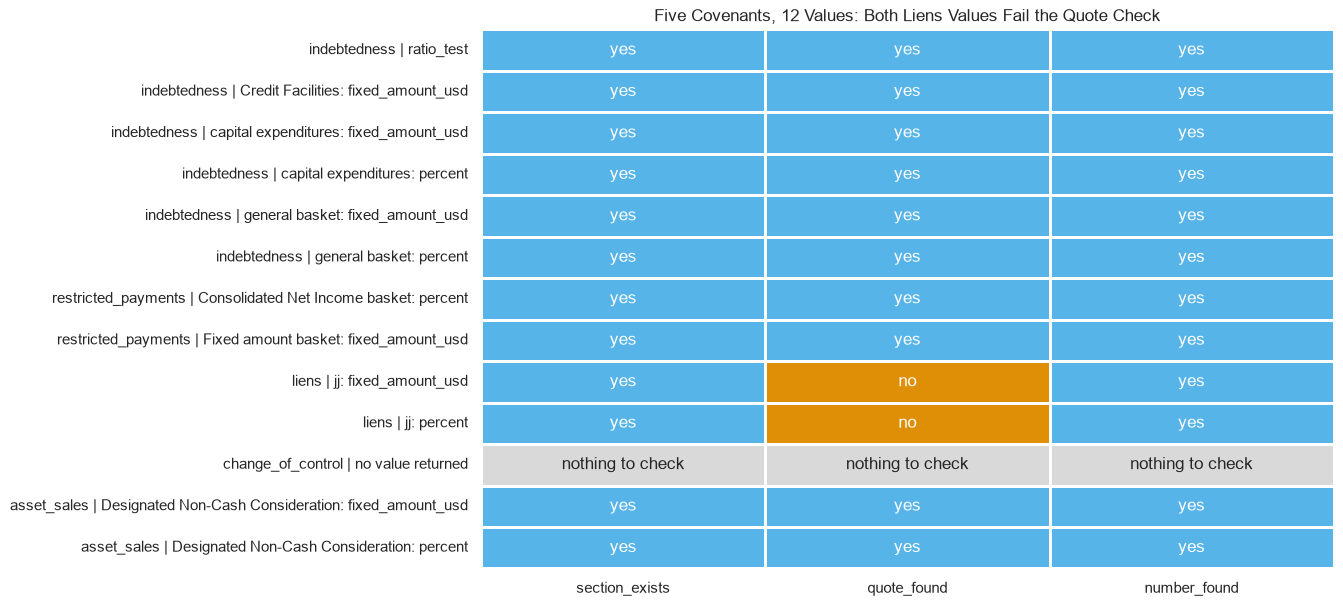

In [37]:
# the grid as tiles: yes in blue, no in orange, nothing to check in grey
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(grid, annot=grid.replace({1: "yes", 0: "no", -1: "nothing to check"}), fmt="", cmap=["0.85", "#DE8F05", "#56B4E9"], vmin=-1, vmax=1, cbar=False, linewidths=1, ax=ax)
ax.set(ylabel="", title="Five Covenants, 12 Values: Both Liens Values Fail the Quote Check")
plt.show()

Liens: both values fail the quote check, though their numbers are in their quote; every other value passes.

Change of control returned no basket: its 101% has no field in the schema, so there is nothing to check.

## Tracing the Two Rejections

In [38]:
# source text: quoted as published
# every value's quote searched in all 107 sections: where the rejected ones are found
plain_sections = {number: plain(section_text(boyd, sections, number)) for number in sections["number"]}
traced = []
for number, kind in COVENANTS:
    for field, value, unit, quote in covenant_values(covenants[number]):
        homes = [n for n, text in plain_sections.items() if plain(quote.text) in text]
        traced.append({"field": field, "cited": quote.section, "found in": homes, "starts": quote.text[:60]})
traced = pd.DataFrame(traced)
print(traced[traced["cited"] != traced["found in"].str[0]].to_string(index=False))
boyd_source("1.01")

               field cited found in                                                       starts
jj: fixed_amount_usd  4.14   [1.01] Liens not specified in the foregoing; provided that the aggr
         jj: percent  4.14   [1.01] Liens not specified in the foregoing; provided that the aggr
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 1.01.


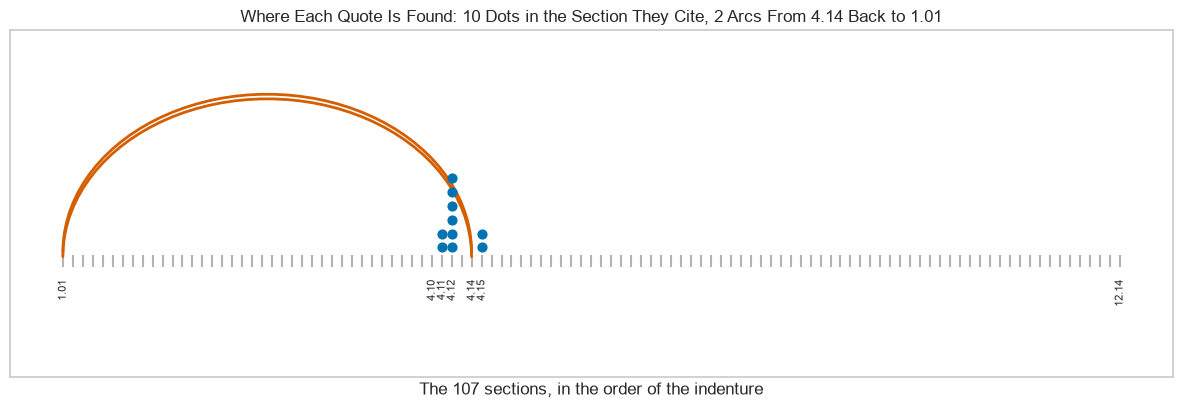

In [39]:
# the 107 sections on one line: a value found where it cites is a dot, one found elsewhere an arc
position = {number: i for i, number in enumerate(sections["number"])}
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.scatter(range(len(sections)), np.zeros(len(sections)), marker="|", color="0.7", s=80)
stacked = {}
for cited, homes in zip(traced["cited"], traced["found in"]):
    a, b = position[cited], position[homes[0]]
    stacked[a] = stacked.get(a, 0) + 1
    if a == b:
        ax.scatter(a, 0.03 * stacked[a], color="C0", s=40, zorder=3)
    else:
        t = np.linspace(0, np.pi, 50)
        ax.plot((a + b) / 2 + (a - b) / 2 * np.cos(t), (a - b) / 2 * np.sin(t) / 60 + 0.01 * stacked[a], color="C3", lw=2)
for number in ["1.01", "4.10", "4.11", "4.12", "4.14", "4.15", "12.14"]:
    ax.text(position[number], -0.04, number, ha="center", fontsize=8, rotation=90, va="top")
ax.set(ylim=(-0.25, 0.5), xticks=[], yticks=[], xlabel="The 107 sections, in the order of the indenture", title="Where Each Quote Is Found: 10 Dots in the Section They Cite, 2 Arcs From 4.14 Back to 1.01")
plt.show()

Both liens values quote clause (jj) of "Permitted Liens", which sits in Section 1.01, and cite 4.14.

The amounts are the text's; the citation is not, so both rows go to a person with their quote.

## The Room Each Response Used

In [40]:
# the nine teaching requests: completion tokens of each, and the tokens and cost of all
nine = {"4.12 first": first, "4.12 change 1": one, "4.12 change 2": two, "4.12 change 3": three, "4.12 fallback": fallback,
        "4.15": responses["4.15"], "4.14": responses["4.14"], "4.10": responses["4.10"], "4.11": responses["4.11"]}
completion = pd.Series({name: run["usage"]["completion_tokens"] for name, run in nine.items()})
prompt = sum(run["usage"]["prompt_tokens"] for run in nine.values())
cost = prompt * float(prompt_price) + completion.sum() * float(completion_price)
print(prompt, "prompt and", completion.sum(), f"completion tokens | US${cost:.7f} at the fallback's list prices |",
      "billed:", [run["usage"]["cost"] for run in nine.values()])

74203 prompt and 11096 completion tokens | US$0.0118587 at the fallback's list prices | billed: [0, 0, 0, 0, 0.0015171, 0, 0, 0, 0]


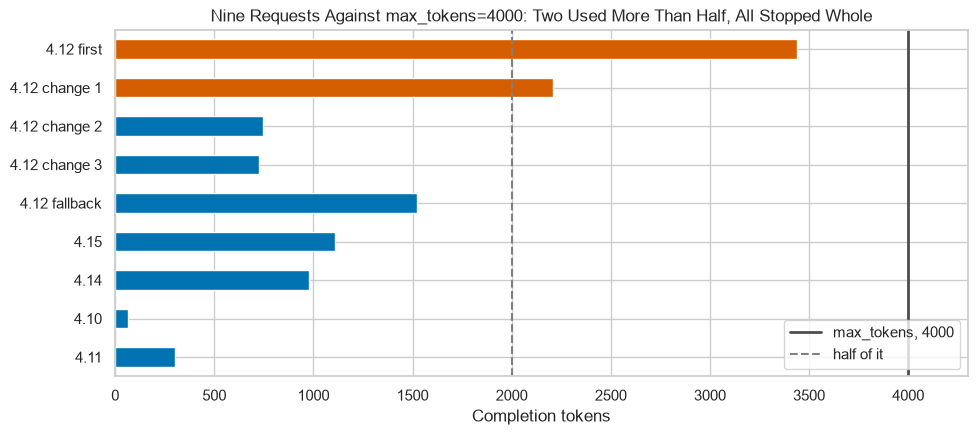

In [41]:
# each request's completion tokens against max_tokens and half of it, those over half in red
ax = completion.plot.barh(figsize=(11, 4.5), color=["C3" if tokens > 2000 else "C0" for tokens in completion])
ax.axvline(4000, color="0.3", lw=2, label="max_tokens, 4000")
ax.axvline(2000, color="0.5", ls="--", label="half of it")
ax.legend(loc="lower right")
ax.invert_yaxis()
ax.set(xlabel="Completion tokens", xlim=(0, 4300), title="Nine Requests Against max_tokens=4000: Two Used More Than Half, All Stopped Whole")
plt.show()

The first response used 3,441 of its 4,000 tokens; Day 11's cap of 2,000 would have cut it.

The 8 free-model requests were billed nothing; at the fallback's list prices all nine come to US$0.0118587.

**A rejected value goes to a person with its quote; a confirmed value is in its quoted sentence, nothing more.**

# The Guardrail

## The System Prompt Went First

In [42]:
# the first message of each of the nine requests as sent: the system prompt, every time
first_messages = [run["request"]["messages"][0] for run in nine.values()]
print(sum(m["role"] == "system" and m["content"] == SYSTEM_PROMPT for m in first_messages), "of", len(first_messages), "requests open with the system prompt")

9 of 9 requests open with the system prompt


## The Instructions Ask What the Text Says

In [43]:
# the day's nine instructions against a list of asking words
ASKING = ["recommend", "rating", "rank", "should", "buy", "sell", "attractive"]
instructions = [instruction("4.12", "indebtedness", CHANGES[:k]) for k in range(4)]
instructions += [instruction(number, kind, CHANGES) for number, kind in COVENANTS[1:] + [("4.17", "affiliate_transactions")]]
asking = re.compile(r"\b(?:" + "|".join(ASKING) + r")\w*", flags=re.IGNORECASE)
print(len(instructions), "instructions | asking words found:", sorted({w for text in instructions for w in asking.findall(text)}))

9 instructions | asking words found: []


In [44]:
# the same search on one sentence written to fail it, held in a variable and never sent
planted = "Rank these baskets by size."
print("in the planted sentence:", asking.findall(planted))

in the planted sentence: ['Rank']


Every instruction asks what a section states, in the schema's fields.

The build runs a longer list over every prompt the course sends.

**The course asks what the document says, and its own code checks that it did.**

# Insights and Conclusion

Section 1.01 holds 148 definitions; Section 4.12 uses 36 of them directly, and 65 with the terms inside those 36.

Code found every amount and percentage of the five covenants before any request was sent.

Four small classes made every response checkable: a number, a quote, a section.

The schema has no field for a multiple, so 4.5 times Consolidated EBITDA went into `percent`; the third sentence removed it.

Of 12 values in five covenants, 10 passed; the 2 liens values cite 4.14 and quote Section 1.01.

Nine teaching requests: 74,203 prompt and 11,096 completion tokens, US$0.0118587 at the fallback's list prices.

**Extract with a schema, check with code, keep what the text holds.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Name an indenture's parties, articles and covenant sections.
* Build a dictionary of defined terms, and list the terms a section uses at depth 1 and 2.
* Read amounts, percentages and a ratio test from a covenant with named groups.
* Write a schema with pydantic and validate a response against it.
* Send an extraction request for JSON, and read `finish_reason` before parsing.
* Check every extracted number against its quote and its cited section.
* Change a prompt one sentence at a time, and trace a rejected value to where its quote really sits.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [45]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Transactions With Affiliates**

Q. Extract Section 4.17 with `extract`, kind `"affiliate_transactions"`, and the three sentences in `CHANGES`. Store the number of values in its checked table in `ex1_checked` and the number that pass in `ex1_passed`.

In [46]:
# LLM response
# Section 4.17 with the three sentences, then its checked table
affiliates = extract("4.17", "affiliate_transactions", CHANGES)
ex1_table = check_extraction(Covenant.model_validate(json.loads(affiliates["content"])))
ex1_checked = len(ex1_table)
ex1_passed = int(ex1_table["passed"].sum())
print(ex1_table[["field", "value", "section", "passed"]].to_string(index=False))
print("amounts code finds in 4.17:", re.findall(AMOUNT, section_text(boyd, sections, "4.17")))
llm_line(affiliates)

                                  field    value section  passed
Affiliate Transaction: fixed_amount_usd 25000000    4.17    True
amounts code finds in 4.17: ['$25,000,000', '$50,000,000']
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The one value returned passes; code finds a second dollar amount in 4.17 that the response left out, and the checks test only what comes back.

In [47]:
check("Exercise 1 the values checked", ex1_checked, 1)
check("Exercise 1 the values that pass", ex1_passed, 1)

Exercise 1 the values checked: correct
Exercise 1 the values that pass: correct


### Exercise 2

**Section 4.12 Without Its Definitions**

Q. Extract Section 4.12 with the three sentences and `with_definitions=False`. Store its checked table in `ex2_table`, the number of values in `ex2_checked` and the number that pass in `ex2_passed`.

In [48]:
# LLM response
# Section 4.12 with the three sentences and no definitions, then its checked table
bare = extract("4.12", "indebtedness", CHANGES, with_definitions=False)
ex2_table = check_extraction(Covenant.model_validate(json.loads(bare["content"])))
ex2_checked = len(ex2_table)
ex2_passed = int(ex2_table["passed"].sum())
print(ex2_checked, "values,", ex2_passed, "pass |", bare["usage"]["prompt_tokens"], "prompt tokens against", three["usage"]["prompt_tokens"], "with the definitions")
print(ex2_table.loc[~ex2_table["passed"], ["field", "value"]].to_string(index=False))
llm_line(bare)

7 values, 6 pass | 3703 prompt tokens against 9468 with the definitions
                     field  value
Credit Facilities: percent    4.5
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


Without the definitions the request is far smaller, and the 4.5 multiple is back in `percent`: the same three sentences, a different answer.

In [49]:
check("Exercise 2 the values checked", ex2_checked, 7)
check("Exercise 2 the values that pass", ex2_passed, 6)

Exercise 2 the values checked: correct
Exercise 2 the values that pass: correct


### Exercise 3

**Why Each Value Failed**

Q. Write `failed_checks(table)`, which returns the rows of a checked table that did not pass, with a column `reason`: "section not in the table" when `section_exists` is False, else "quote not in the section" when `quote_found` is False, else "number not in the quote". Store the reasons for `ex2_table` as a list in `ex3_reasons`.

In [50]:
# the rows that did not pass, each with the first check it failed (np.where inside np.where, Course 1)
def failed_checks(table):
    """The rows of a checked table that did not pass, with the reason each failed."""
    failed = table[~table["passed"]].copy()
    failed["reason"] = np.where(~failed["section_exists"], "section not in the table",
                                np.where(~failed["quote_found"], "quote not in the section", "number not in the quote"))
    return failed


ex3_reasons = failed_checks(ex2_table)["reason"].tolist()
print(ex3_reasons)
print(failed_checks(table)[["field", "reason"]].to_string(index=False))

['number not in the quote']
               field                   reason
jj: fixed_amount_usd quote not in the section
         jj: percent quote not in the section


On the five covenants' table the two liens rows fail for the other reason: their quote is not in Section 4.14.

In [51]:
check("Exercise 3 the reasons", ex3_reasons, ["number not in the quote"])

Exercise 3 the reasons: correct


### Exercise 4: AI check

**A Checker That Repairs**

You asked an AI assistant for a function that checks an extracted covenant against the indenture.
Run it on the extraction below, planted for this exercise: its amount is the one clause (xv) states, but its quote was copied from clause (ix).

In [52]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def checked_values(covenant):
    """Check every number of an extracted covenant against the indenture, and return the checked table."""
    for basket in covenant.baskets:
        amount = basket.fixed_amount_usd
        if amount is not None and not number_found(amount, "USD", plain(basket.quote.text)):
            # read the amount again from the quote
            basket.fixed_amount_usd = int(re.search(r"\$([\d,]+)", basket.quote.text)[1].replace(",", ""))
    return check_extraction(covenant)

In [53]:
# the planted extraction through the checker
PLANTED = {"kind": "indebtedness", "section": "4.12", "title": "Limitation on Indebtedness", "ratio_test": None,
           "baskets": [{"name": "general basket", "fixed_amount_usd": 430000000, "percent": None, "percent_of": None, "greater_of": True,
                        "quote": {"section": "4.12", "text": "not to exceed the greater of (A) $285,000,000 and (B) 5.0% of the Company's Consolidated Total Assets"}}],
           "quote": {"section": "4.12", "text": "Limitation on Indebtedness"}}
print(checked_values(Covenant.model_validate(PLANTED))[["field", "value", "number_found", "passed"]].to_string(index=False))

                           field     value  number_found  passed
general basket: fixed_amount_usd 285000000          True    True


The bug is the "repair": when a value's number is not in its quote, the function overwrites the value with the first dollar amount the quote holds and marks it passed.

The table then holds 285,000,000, a number the extraction never returned, and the failed check is gone.

The fix: report the checked table as it is, so a failed value reaches a person with its quote.

Q. Fix the one wrong idea, run the fixed function on `Covenant.model_validate(PLANTED)`, and store the value it reports in `ex4_value` and its number check in `ex4_found`.

In [54]:
# the fix: the checks report each value as the extraction returned it, and a failed check stays failed
def checked_values(covenant):
    """Check every number of an extracted covenant against the indenture, and return the checked table."""
    return check_extraction(covenant)


ex4_table = checked_values(Covenant.model_validate(PLANTED))
ex4_value = int(ex4_table["value"].iloc[0])
ex4_found = bool(ex4_table["number_found"].iloc[0])
print(ex4_table[["field", "value", "number_found", "passed"]].to_string(index=False))

                           field     value  number_found  passed
general basket: fixed_amount_usd 430000000         False   False


In [55]:
check("Exercise 4 the value reported", ex4_value, 430000000)
check("Exercise 4 the number check", ex4_found, False)

Exercise 4 the value reported: correct
Exercise 4 the number check: correct


## Congratulations!

You took a 63,595-word contract apart: its parties, its twelve articles, and the 148 definitions its covenants are written in.
You found every amount with your own patterns before a model saw a word, then wrote a schema that makes a model return each number with its quote and its section.
You caught a multiple of EBITDA sitting in a percentage field, removed it with one sentence, and traced two liens values from the section they cited back to the one that holds them.
That is the habit of the whole week: the model extracts, and code decides what stays.
In Day 13 you put the baskets of two indentures, fifteen years apart, side by side, and read a table straight from a page of the PDF.

[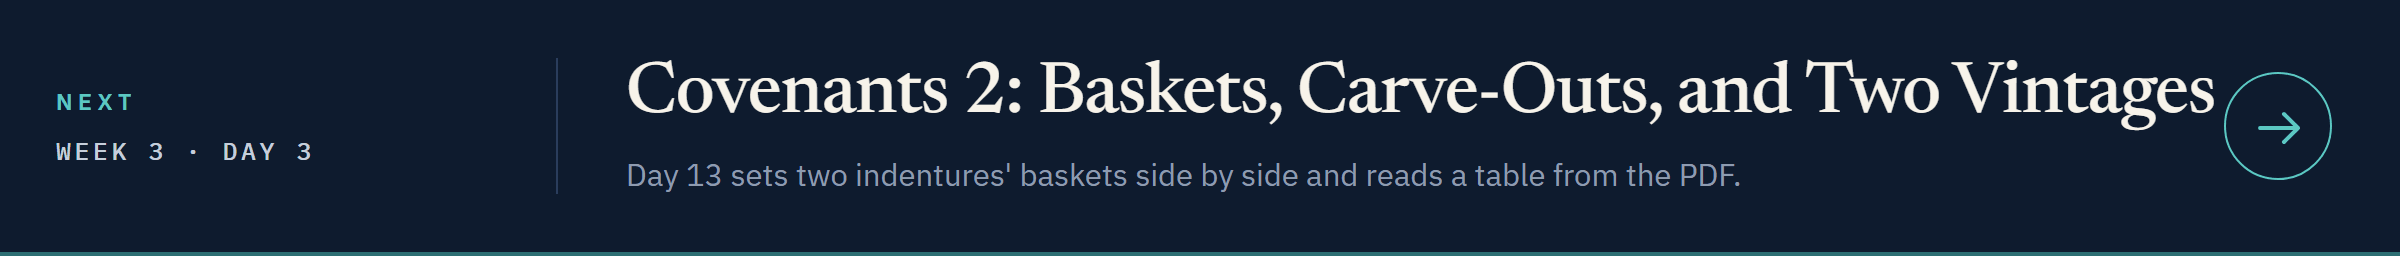](../day3/13_covenants_2_baskets_carve_outs_and_two_vintages.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day3/13_covenants_2_baskets_carve_outs_and_two_vintages.ipynb)